# 05 · Midterm figures and tables (course: Multimodal Deep Learning)
Figures and tables for the midterm report. Reads only data/processed and data/interim.
New EDA uses train + validation periods only (days 19–52); the test period stays closed.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Clone or update the project repository
import os
from google.colab import userdata
token = userdata.get('GH_TOKEN')
REPO = '/content/tevzi'
if not os.path.exists(REPO):
    !git clone -q https://{token}@github.com/emirsalihoglu/tevzi.git {REPO}
else:
    !git -C {REPO} pull -q
!git -C {REPO} log --oneline -1

d14fb04 (HEAD -> main, origin/main, origin/HEAD) Add notebook 05: midterm figures and tables (V1-V2, F05, F12 part 1)


In [3]:
# Make the package importable and prepare Drive folders
import sys
from pathlib import Path
sys.path.insert(0, f'{REPO}/src')
DRIVE = Path('/content/drive/MyDrive/Tevzi')
for sub in ['data/raw', 'data/interim', 'data/processed',
            'results/models', 'results/figures', 'results/tables']:
    (DRIVE / sub).mkdir(parents=True, exist_ok=True)
import tevzi
print('tevzi package:', tevzi.__file__)
print('Drive folder:', DRIVE)

tevzi package: /content/tevzi/src/tevzi/__init__.py
Drive folder: /content/drive/MyDrive/Tevzi


In [4]:
# Inspect processed and interim files: schema and row counts, no data loaded
import pyarrow.parquet as pq

def show_dir(folder):
    for p in sorted(folder.glob('*')):
        size = p.stat().st_size / 1e6
        if p.suffix == '.parquet':
            f = pq.ParquetFile(p)
            names = f.schema_arrow.names
            print(f'{p.name}: {f.metadata.num_rows:,} rows, {len(names)} cols, {size:.1f} MB')
            print('    ', names[:25], '...' if len(names) > 25 else '')
        else:
            print(f'{p.name}: {size:.2f} MB')

PROC, INTERIM = DRIVE / 'data/processed', DRIVE / 'data/interim'
print('=== processed'); show_dir(PROC)
print('\n=== interim'); show_dir(INTERIM)

=== processed
jobs_flags.parquet: 1,055,501 rows, 15 cols, 40.7 MB
     ['job_name', 'user', 'status', 'submit_time', 'end_time', 'first_start', 'n_tasks', 'req_gpu_total', 'req_cpu_total', 'req_mem_total', 'R2_cpu_only', 'm2_arrival', 'm2_occupancy', 'model', 'first_rule'] 
m1_features.parquet: 714,273 rows, 47 cols, 77.7 MB
     ['job_name', 'main_plan_gpu', 'main_plan_cpu', 'main_plan_mem', 'main_inst_num', 'req_gpu_total', 'req_cpu_total', 'req_mem_total', 'main_gpu_type', 'gpu_fractional', 'mem_per_gpu', 'cpu_per_gpu', 'n_tasks', 'has_ps', 'has_evaluator', 'n_ps_inst', 'total_inst', 'main_task', 'user', 'workload', 'workload_missing', 'grp_rt_n', 'grp_rt_mean', 'grp_rt_std', 'grp_rt_last'] ...
m2_capacities.json: 0.00 MB
m2_grid.parquet: 19,858 rows, 28 cols, 2.6 MB
     ['t', 'arr_count', 'arr_gpu', 'occ_gpu', 'occ_cpu', 'occ_mem', 'pressure', 'use_gpu', 'ALL:pool_occ', 'ALL:pool_pressure', 'ALL:pool_arr_gpu', 'ALL:pool_use_gpu', 'P100:pool_occ', 'P100:pool_pressure', 'P100:pool_

In [5]:
# Figure helper: one style for all figures, saved as results/figures/F##_name.png
import matplotlib.pyplot as plt
FIG = DRIVE / 'results/figures'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def save_fig(fig, fid, name):
    path = FIG / f'F{fid:02d}_{name}.png'
    fig.savefig(path, bbox_inches='tight')
    print('saved', path.name)

In [ ]:
# T3: matching statistics — does every model job have every modality, and are they aligned in time?
import numpy as np, pandas as pd, pyarrow.parquet as pq

jf = pd.read_parquet(PROC / 'jobs_flags.parquet', columns=['job_name', 'submit_time', 'model'])
tg = pd.read_parquet(PROC / 'targets.parquet',
                     columns=['job_name', 'period', 'submit_day', 'purged', 'has_usage'])
m1 = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'grp_rt_n', 'usr_rt_n'])
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'submit', 'pool_key', 'k_last'])
grid_t = pd.read_parquet(PROC / 'm2_grid.parquet', columns=['t'])['t'].to_numpy()
grid_cols = pq.ParquetFile(PROC / 'm2_grid.parquet').schema_arrow.names

# 1) Keys: unique in every table, and exactly the model-set jobs everywhere
model_jobs = set(jf.loc[jf['model'].astype(bool), 'job_name'])
print(f'model jobs: {len(model_jobs):,}')
for name, df in [('targets', tg), ('m1', m1), ('m2_snapshots', sn)]:
    print(f'  {name:13s} rows {len(df):,} | unique key: {df.job_name.is_unique} '
          f'| same job set: {set(df.job_name) == model_jobs}')

# 2) Time alignment: snapshot time = submission time; k_last = grid step just before submission
d = sn.merge(jf[['job_name', 'submit_time']], on='job_name', how='left')
print('\nsnapshot submit == job submit_time:', bool(np.allclose(d['submit'], d['submit_time'])))
k = d['k_last'].to_numpy()
print(f'k_last range: {k.min()} .. {k.max()} (grid has {len(grid_t):,} steps, '
      f'step {np.diff(grid_t[:2])[0]:.0f} s)')
gap = d['submit'].to_numpy() - grid_t[k]
print('submit - t[k_last] in seconds:')
print(pd.Series(gap).describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_string())

# 3) Pools: every job's pool has its columns in the grid
pools = sn['pool_key'].value_counts()
print('\npool_key counts:'); print(pools.to_string())
missing = [p for p in pools.index if f'{p}:pool_occ' not in grid_cols]
print('pools without grid columns:', missing)

# 4) Coverage per period (counts are descriptive; no target values are used)
t3 = (tg.merge(m1, on='job_name').merge(sn[['job_name', 'k_last']], on='job_name'))
t3['m2_full_window'] = t3['k_last'] >= 23          # 24 past steps available
t3['grp_history'] = t3['grp_rt_n'].fillna(0) > 0
t3['usr_history'] = t3['usr_rt_n'].fillna(0) > 0
order = t3.groupby('period')['submit_day'].min().sort_values().index
agg = (t3.groupby('period')
         .agg(jobs=('job_name', 'size'), m2_full_window=('m2_full_window', 'sum'),
              usage_label=('has_usage', 'sum'), grp_history=('grp_history', 'sum'),
              usr_history=('usr_history', 'sum'), purged=('purged', 'sum'))
         .reindex(order))
agg.loc['total'] = agg.sum()
for c in ['m2_full_window', 'usage_label', 'grp_history', 'usr_history', 'purged']:
    agg[c + '_%'] = (100 * agg[c] / agg['jobs']).round(1)
print(); print(agg.to_string())
agg.to_csv(DRIVE / 'results/tables/midterm_T3_matching.csv')
print('saved midterm_T3_matching.csv')

model jobs: 714,273
  targets       rows 714,273 | unique key: True | same job set: True
  m1            rows 714,273 | unique key: True | same job set: True
  m2_snapshots  rows 714,273 | unique key: True | same job set: True

snapshot submit == job submit_time: True
k_last range: 160 .. 19855 (grid has 19,858 steps, step 300 s)
submit - t[k_last] in seconds:
count    714273.0
mean        150.5
std          86.7
min           1.0
1%            4.0
50%         151.0
99%         297.0
max         300.0

pool_key counts:
pool_key
ALL        456357
T4         183406
P100        49366
V100        16460
V100M32      8684
pools without grid columns: []

          jobs  m2_full_window  usage_label  grp_history  usr_history  purged  m2_full_window_%  usage_label_%  grp_history_%  usr_history_%  purged_%
period                                                                                                                                                
warmup  123831          123831         150

log_run_time == log1p(run_time): True
T4: 34,343 candidates, pool_pressure in [0.000, 0.009], median wait 3 s -> 96abd92db1f26f617307b31f
V100: 301 candidates, pool_pressure in [0.457, 60.000], median wait 116 s -> 6c21ae223da5fb62fcba877a
saved F07_matching_example.png


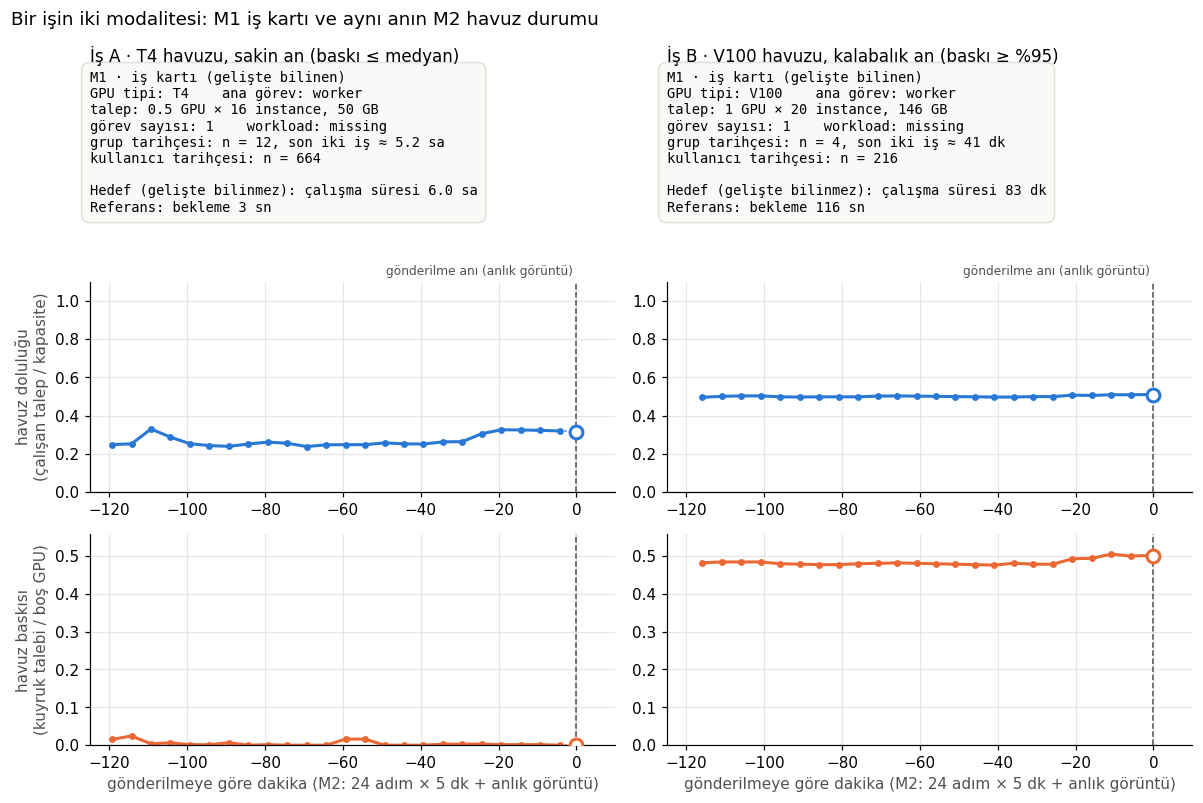

İş A · T4 havuzu, sakin an (baskı ≤ medyan) | 96abd92db1f26f617307b31f | submit 2141877.0 | k_last 5491 | snapshot occ/pressure 0.317 0.0
İş B · V100 havuzu, kalabalık an (baskı ≥ %95) | 6c21ae223da5fb62fcba877a | submit 2964571.0 | k_last 8234 | snapshot occ/pressure 0.51 0.501


In [ ]:
# F07: matching evidence — a calm T4 job and a busy V100 job: M1 card + M2 window, submission marked
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

C_OCC, C_PRES = '#2a78d6', '#eb6834'          # categorical slots 1-2 (validated palette)
INK2, MUTED, PANEL, EDGE = '#52514e', '#898781', '#f9f9f7', '#e1e0d9'

tg = pd.read_parquet(PROC / 'targets.parquet',
                     columns=['job_name', 'period', 'purged', 'run_time', 'log_run_time', 'wait_time'])
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet',
                     columns=['job_name', 'submit', 'pool_key', 'k_last', 'pool_occ', 'pool_pressure'])
m1c = ['job_name', 'main_gpu_type', 'main_task', 'main_plan_gpu', 'main_plan_mem', 'main_inst_num',
       'n_tasks', 'workload', 'grp_rt_n', 'grp_rt_last2', 'usr_rt_n']
m1 = pd.read_parquet(PROC / 'm1_features.parquet', columns=m1c)
grid = pd.read_parquet(PROC / 'm2_grid.parquet')
print('log_run_time == log1p(run_time):', bool(np.allclose(tg.log_run_time, np.log1p(tg.run_time))))

# Candidates: train/val, not purged, with group history (so the M1 card carries history)
J = (tg[tg.period.isin(['train', 'val']) & ~tg.purged.astype(bool)]
       .merge(sn, on='job_name').merge(m1, on='job_name'))
J = J[J.grp_rt_n.fillna(0) > 0]

def pick(pool, lo_q, hi_q):
    """Representative, not cherry-picked: the job whose wait is closest to the subset median."""
    s = J[J.pool_key == pool]
    lo, hi = s.pool_pressure.quantile([lo_q, hi_q])
    s = s[s.pool_pressure.between(lo, hi)]
    med = s.wait_time.median()
    r = s.iloc[int(np.argmin((s.wait_time - med).abs().to_numpy()))]
    print(f'{pool}: {len(s):,} candidates, pool_pressure in [{lo:.3f}, {hi:.3f}], '
          f'median wait {med:.0f} s -> {r.job_name}')
    return r

def fmt(sec):
    sec = float(sec)
    return f'{sec:.0f} sn' if sec < 120 else f'{sec/60:.0f} dk' if sec < 7200 else f'{sec/3600:.1f} sa'

def card(r):
    return '\n'.join([
        'M1 · iş kartı (gelişte bilinen)',
        f'GPU tipi: {r.main_gpu_type}    ana görev: {r.main_task}',
        f'talep: {r.main_plan_gpu/100:g} GPU × {r.main_inst_num:.0f} instance, {r.main_plan_mem:.0f} GB',
        f'görev sayısı: {r.n_tasks:.0f}    workload: {r.workload}',
        f'grup tarihçesi: n = {r.grp_rt_n:g}, son iki iş ≈ {fmt(np.expm1(r.grp_rt_last2))}',
        f'kullanıcı tarihçesi: n = {r.usr_rt_n:g}',
        '',
        f'Hedef (gelişte bilinmez): çalışma süresi {fmt(r.run_time)}',
        f'Referans: bekleme {fmt(r.wait_time)}',
    ])

jobs = [('İş A · T4 havuzu, sakin an (baskı ≤ medyan)', pick('T4', 0.0, 0.5)),
        ('İş B · V100 havuzu, kalabalık an (baskı ≥ %95)', pick('V100', 0.95, 1.0))]

t = grid['t'].to_numpy()
fig, axes = plt.subplots(3, 2, figsize=(11, 7.4), gridspec_kw={'height_ratios': [0.8, 1, 1]})
rows = [('pool_occ', C_OCC, 'havuz doluluğu\n(çalışan talep / kapasite)'),
        ('pool_pressure', C_PRES, 'havuz baskısı\n(kuyruk talebi / boş GPU)')]
for j, (title, r) in enumerate(jobs):
    axes[0, j].axis('off')
    axes[0, j].set_title(title, loc='left', fontsize=11)
    axes[0, j].text(0, 1, card(r), va='top', fontsize=9, family='DejaVu Sans Mono',
                    bbox=dict(boxstyle='round,pad=0.6', fc=PANEL, ec=EDGE))
    ks = np.arange(int(r.k_last) - 23, int(r.k_last) + 1)
    x = (t[ks] - r.submit) / 60
    for i, (ch, col, lab) in enumerate(rows, start=1):
        ax = axes[i, j]
        y = grid[f'{r.pool_key}:{ch}'].to_numpy()[ks]
        ax.plot(x, y, color=col, lw=2, marker='o', ms=3.5)
        ax.plot([x[-1], 0], [y[-1], r[ch]], color=col, lw=1.2, ls=':')
        ax.scatter([0], [r[ch]], s=70, facecolor='white', edgecolor=col, lw=2, zorder=3)
        ax.axvline(0, color=INK2, lw=1, ls='--')
        ax.set_xlim(-125, 10)
        if j == 0:
            ax.set_ylabel(lab, color=INK2)
        if i == 1:
            ax.text(-1, 1.02, 'gönderilme anı (anlık görüntü)', transform=ax.get_xaxis_transform(),
                    ha='right', va='bottom', fontsize=8, color=INK2)
        if i == 2:
            ax.set_xlabel('gönderilmeye göre dakika (M2: 24 adım × 5 dk + anlık görüntü)', color=INK2)
for i in (1, 2):                                    # same y-scale per channel, so A and B compare
    top = 1.1 * max(axes[i, 0].get_ylim()[1], axes[i, 1].get_ylim()[1], 1.0 if i == 1 else 0)
    for j in (0, 1):
        axes[i, j].set_ylim(0, top)
fig.suptitle('Bir işin iki modalitesi: M1 iş kartı ve aynı anın M2 havuz durumu', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 7, 'matching_example')
plt.show()
for title, r in jobs:
    print(title, '|', r.job_name, '| submit', r.submit, '| k_last', r.k_last,
          '| snapshot occ/pressure', round(float(r.pool_occ), 3), round(float(r.pool_pressure), 3))

jobs (train+val, not purged): 369,675 | with usage label: 358,322 (96.9%)
saved F03_target_distributions.png


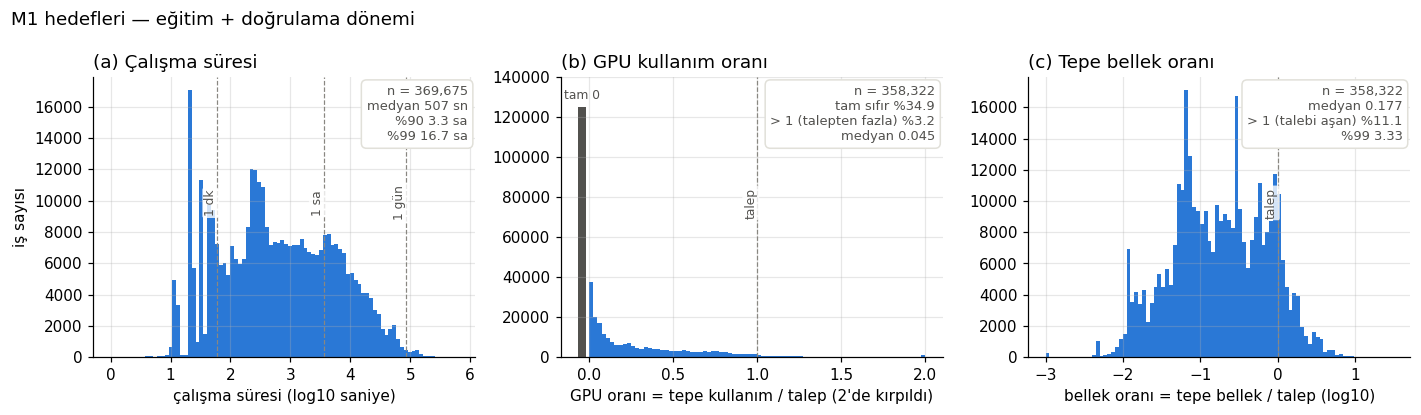

In [7]:
# F03: M1 target distributions (train + validation): run time, GPU ratio, peak memory ratio
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, INK2, MUTED = '#2a78d6', '#52514e', '#898781'
tg = pd.read_parquet(PROC / 'targets.parquet',
                     columns=['job_name', 'period', 'purged', 'run_time', 'gpu_ratio', 'mem_ratio', 'has_usage'])
E = tg[tg.period.isin(['train', 'val']) & ~tg.purged.astype(bool)]
U = E[E.has_usage.astype(bool)]
print(f'jobs (train+val, not purged): {len(E):,} | with usage label: {len(U):,} ({100*len(U)/len(E):.1f}%)')

def note(ax, lines):
    ax.text(0.98, 0.97, '\n'.join(lines), transform=ax.transAxes, ha='right', va='top', fontsize=8.5,
            color=INK2, bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='#e1e0d9'))

def vlabel(ax, x, text):
    ax.text(x, 0.55, text, transform=ax.get_xaxis_transform(), rotation=90, ha='right', va='center',
            fontsize=8, color=INK2, bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# (a) run time on log10 seconds
ax = axes[0]
x = np.log10(E.run_time.clip(lower=1))
ax.hist(x, bins=90, color=BLUE)
for sec, lab in [(60, '1 dk'), (3600, '1 sa'), (86400, '1 gün')]:
    ax.axvline(np.log10(sec), color=MUTED, ls='--', lw=0.8)
    vlabel(ax, np.log10(sec), lab)
q = E.run_time.quantile([0.5, 0.9, 0.99])
note(ax, [f'n = {len(E):,}', f'medyan {q[0.5]:.0f} sn', f'%90 {q[0.9]/3600:.1f} sa', f'%99 {q[0.99]/3600:.1f} sa'])
ax.set_xlabel('çalışma süresi (log10 saniye)'); ax.set_ylabel('iş sayısı'); ax.set_title('(a) Çalışma süresi', loc='left')

# (b) GPU ratio: exact zeros shown as their own bar, display clipped at 2
ax = axes[1]
g = U.gpu_ratio
zero, over = (g == 0).mean(), (g > 1).mean()
ax.hist(g[(g > 0)].clip(upper=2), bins=np.linspace(0, 2, 81), color=BLUE)
ax.bar(-0.04, (g == 0).sum(), width=0.05, color=INK2)
ax.axvline(1, color=MUTED, ls='--', lw=0.8)
ax.set_ylim(0, (g == 0).sum() * 1.12)
ax.text(-0.04, (g == 0).sum() * 1.02, 'tam 0', fontsize=8, color=INK2, ha='center', va='bottom')
vlabel(ax, 1, 'talep')
note(ax, [f'n = {len(U):,}', f'tam sıfır %{100*zero:.1f}', f'> 1 (talepten fazla) %{100*over:.1f}', f'medyan {g.median():.3f}'])
ax.set_xlabel('GPU oranı = tepe kullanım / talep (2\'de kırpıldı)'); ax.set_title('(b) GPU kullanım oranı', loc='left')

# (c) peak memory ratio on log10 scale
ax = axes[2]
m = U.mem_ratio
ax.hist(np.log10(m.clip(lower=1e-3)), bins=90, color=BLUE)
ax.axvline(0, color=MUTED, ls='--', lw=0.8)
vlabel(ax, 0, 'talep')
note(ax, [f'n = {len(U):,}', f'medyan {m.median():.3f}', f'> 1 (talebi aşan) %{100*(m > 1).mean():.1f}',
          f'%99 {m.quantile(0.99):.2f}'])
ax.set_xlabel('bellek oranı = tepe bellek / talep (log10)'); ax.set_title('(c) Tepe bellek oranı', loc='left')

fig.suptitle('M1 hedefleri — eğitim + doğrulama dönemi', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 3, 'target_distributions')
plt.show()

In [ ]:
# T7: summary statistics (train + validation) for targets, numeric M1 features and M2 snapshot channels
import numpy as np, pandas as pd

keep = lambda df: df[df.job_name.isin(E.job_name)]
tgt = keep(pd.read_parquet(PROC / 'targets.parquet',
                           columns=['job_name', 'run_time', 'log_run_time', 'wait_time', 'gpu_ratio', 'mem_ratio']))
m1n = keep(pd.read_parquet(PROC / 'm1_features.parquet'))
m1n = m1n[['job_name'] + [c for c in m1n.columns if c != 'job_name' and pd.api.types.is_numeric_dtype(m1n[c])]]
snp = keep(pd.read_parquet(PROC / 'm2_snapshots.parquet')).drop(columns=['submit', 'pool_key', 'k_last'])

def describe(df, modality):
    x = df.drop(columns='job_name').copy()
    for c in x.columns:                      # booleans -> 0/1 floats (mean = share)
        if x[c].dtype.kind == 'b' or str(x[c].dtype) == 'boolean':
            x[c] = x[c].to_numpy(dtype=float, na_value=np.nan)
    out = pd.DataFrame({
        'modality': modality, 'n': x.notna().sum(), 'missing_%': (100 * x.isna().mean()).round(1),
        'mean': x.mean(), 'std': x.std(), 'min': x.min(), 'q25': x.quantile(0.25),
        'median': x.median(), 'q75': x.quantile(0.75), 'q99': x.quantile(0.99), 'max': x.max()})
    return out

T7 = pd.concat([describe(tgt, 'target'), describe(m1n, 'M1'), describe(snp, 'M2 snapshot')])
T7.index.name = 'feature'
T7.to_csv(DRIVE / 'results/tables/midterm_T7_summary_stats.csv')
print(f'T7: {len(T7)} rows saved -> midterm_T7_summary_stats.csv')
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    print(T7.drop(columns=['min', 'q25', 'q75']).to_string())

T7: 58 rows saved -> midterm_T7_summary_stats.csv
                        modality       n  missing_%      mean       std    median       q99       max
feature                                                                                              
run_time                  target  369675          0      4831  1.51e+04       507 6.027e+04 6.264e+05
log_run_time              target  369675          0     6.406     2.185      6.23     11.01     13.35
wait_time                 target  369675          0     402.3      4299         7      8331 5.543e+05
gpu_ratio                 target  358322        3.1    0.2174     0.411     0.045     1.349        70
mem_ratio                 target  358322        3.1    0.4283     0.745     0.177     3.327     30.45
main_plan_gpu                 M1  369675          0     67.38     55.02        50       200       800
main_plan_cpu                 M1  369675          0     698.8     462.5       600      2000      9000
main_plan_mem                 M1

saved F04_requests_representation.png


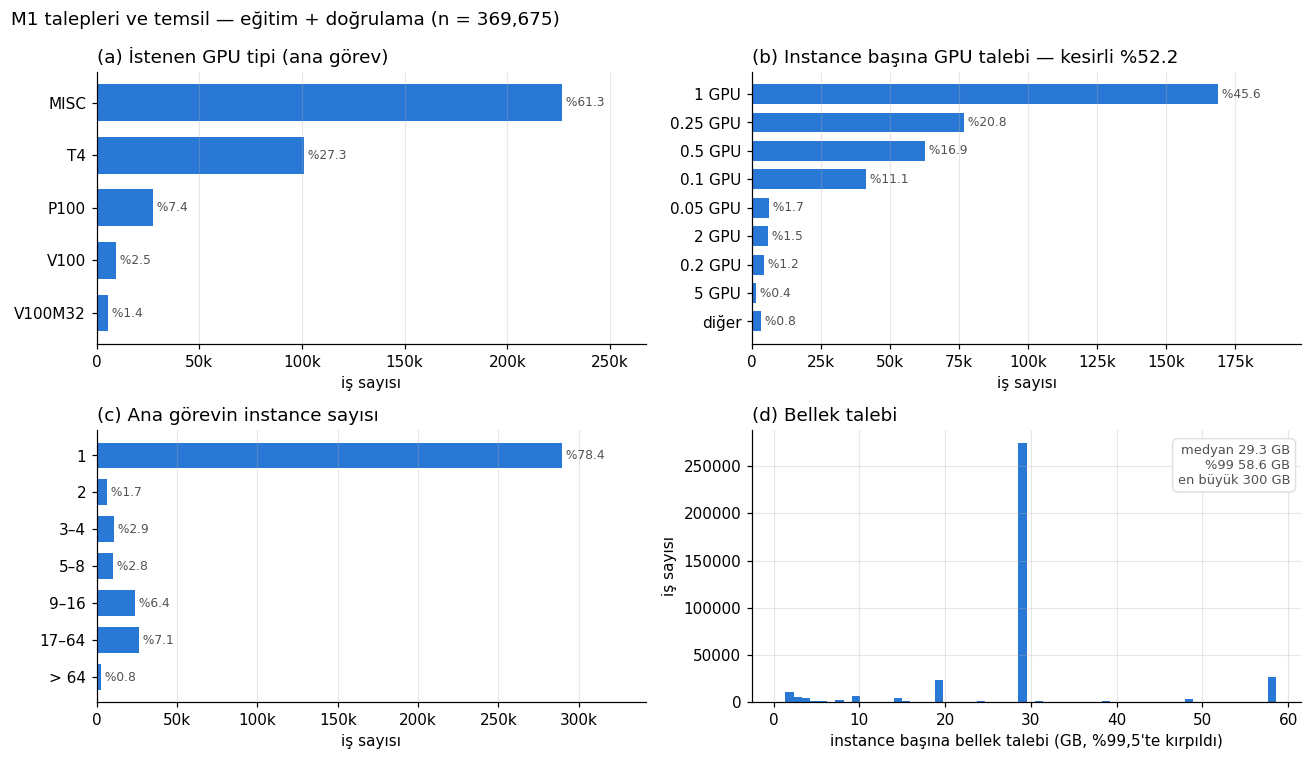

In [ ]:
# F04: M1 requests and representation (train + validation): GPU type, GPU per instance, instances, memory
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, INK2 = '#2a78d6', '#52514e'
r = pd.read_parquet(PROC / 'm1_features.parquet',
                    columns=['job_name', 'main_gpu_type', 'main_plan_gpu', 'main_inst_num', 'main_plan_mem', 'gpu_fractional'])
r = r[r.job_name.isin(E.job_name)]
n = len(r)

def hbar(ax, counts, title, xlabel='iş sayısı'):
    counts = counts.iloc[::-1]
    ax.barh(counts.index.astype(str), counts.values, color=BLUE, height=0.7)
    for y, v in enumerate(counts.values):
        ax.text(v, y, f' %{100*v/n:.1f}', va='center', fontsize=8, color=INK2)
    ax.set_xlim(0, counts.max() * 1.18); ax.set_xlabel(xlabel); ax.set_title(title, loc='left')
    ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k' if v >= 1000 else f'{v:.0f}'))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
hbar(axes[0, 0], r.main_gpu_type.astype(str).value_counts(), '(a) İstenen GPU tipi (ana görev)')

g = (r.main_plan_gpu / 100).round(2)
top = g.value_counts().head(8)
gc = pd.concat([top, pd.Series({'diğer': n - top.sum()})])
gc.index = [f'{v:g} GPU' if v != 'diğer' else v for v in gc.index]
hbar(axes[0, 1], gc, f'(b) Instance başına GPU talebi — kesirli %{100*r.gpu_fractional.mean():.1f}')

bins = [0, 1, 2, 4, 8, 16, 64, np.inf]
labels = ['1', '2', '3–4', '5–8', '9–16', '17–64', '> 64']
ic = pd.cut(r.main_inst_num, bins=bins, labels=labels).value_counts().reindex(labels)
hbar(axes[1, 0], ic, '(c) Ana görevin instance sayısı')

ax = axes[1, 1]
mem = r.main_plan_mem
ax.hist(mem.clip(upper=mem.quantile(0.995)), bins=60, color=BLUE)
ax.set_xlabel('instance başına bellek talebi (GB, %99,5\'te kırpıldı)'); ax.set_ylabel('iş sayısı')
ax.set_title('(d) Bellek talebi', loc='left')
ax.text(0.98, 0.95, f'medyan {mem.median():.1f} GB\n%99 {mem.quantile(0.99):.1f} GB\nen büyük {mem.max():.0f} GB',
        transform=ax.transAxes, ha='right', va='top', fontsize=8.5, color=INK2,
        bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='#e1e0d9'))

fig.suptitle(f'M1 talepleri ve temsil — eğitim + doğrulama (n = {n:,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 4, 'requests_representation')
plt.show()

levels: main_task 10 | workload 10
saved F15_categorical_features.png


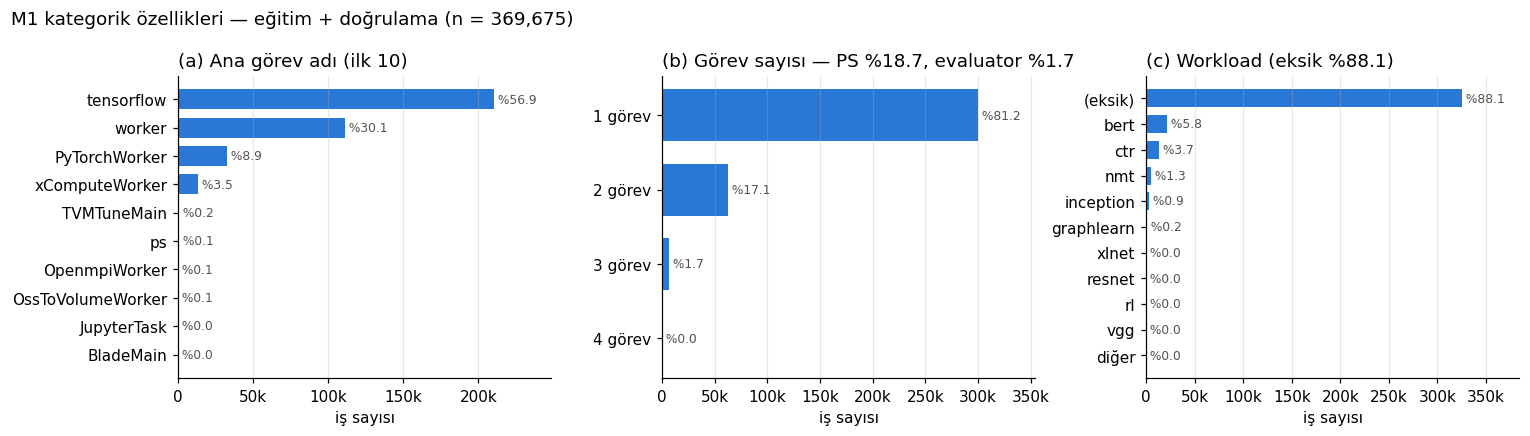

In [ ]:
# F15: M1 categorical features (train + validation): main task, number of tasks, workload
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

c = pd.read_parquet(PROC / 'm1_features.parquet',
                    columns=['job_name', 'main_task', 'n_tasks', 'has_ps', 'has_evaluator', 'workload', 'workload_missing'])
c = c[c.job_name.isin(E.job_name)]
n = len(c)
print('levels: main_task', c.main_task.nunique(), '| workload', c.workload.nunique())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
hbar(axes[0], c.main_task.astype(str).value_counts().head(10), '(a) Ana görev adı (ilk 10)')
nt = c.n_tasks.astype(int).value_counts().sort_index()
nt.index = [f'{k} görev' for k in nt.index]
hbar(axes[1], nt, f'(b) Görev sayısı — PS %{100*c.has_ps.mean():.1f}, evaluator %{100*c.has_evaluator.mean():.1f}')
w = c.loc[~c.workload_missing.astype(bool), 'workload'].astype(str).value_counts()
wc = pd.concat([pd.Series({'(eksik)': int(c.workload_missing.sum())}), w.head(9),
                pd.Series({'diğer': int(w.iloc[9:].sum())})])
hbar(axes[2], wc.sort_values(ascending=False), f'(c) Workload (eksik %{100*c.workload_missing.mean():.1f})')
fig.suptitle(f'M1 kategorik özellikleri — eğitim + doğrulama (n = {n:,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 15, 'categorical_features')
plt.show()

jobs 369,675 | users 1,002 | groups 115,619 | jobs without group tag 103
saved F16_user_group_concentration.png


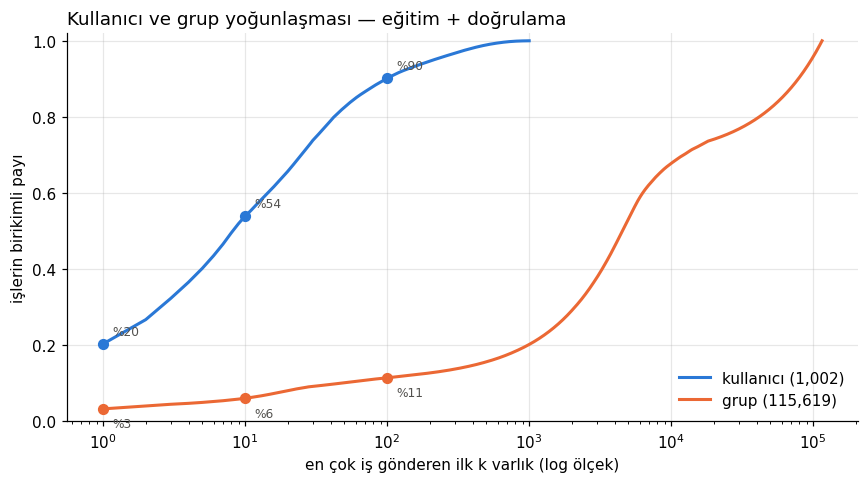

   entity      n  top1_%  top10_%  top100_%  singletons
kullanıcı   1002    20.4     53.9      90.1          84
     grup 115619     3.3      6.1      11.5       97618


In [ ]:
# F16: concentration of jobs over users and groups (train + validation)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, INK2 = '#2a78d6', '#eb6834', '#52514e'
u = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'user'])
u = u[u.job_name.isin(E.job_name)]
jt = pd.read_parquet(INTERIM / 'pai_job_table.parquet', columns=['job_name', 'inst_id'])
gt = pd.read_parquet(INTERIM / 'pai_group_tag_table.parquet', columns=['inst_id', 'group'])
grp = u[['job_name']].merge(jt, on='job_name', how='left').merge(gt, on='inst_id', how='left')
print(f'jobs {len(u):,} | users {u.user.nunique():,} | groups {grp.group.nunique():,} '
      f'| jobs without group tag {grp.group.isna().sum():,}')

def top_share(keys):
    cnt = keys.value_counts().to_numpy()               # descending
    k = np.arange(1, len(cnt) + 1)
    return k, np.cumsum(cnt) / cnt.sum(), cnt

fig, ax = plt.subplots(figsize=(8, 4.5))
rows = []
for keys, col, name in [(u.user.astype(str), BLUE, 'kullanıcı'), (grp.group.dropna().astype(str), ORANGE, 'grup')]:
    k, s, cnt = top_share(keys)
    ax.plot(k, s, color=col, lw=2, label=f'{name} ({len(k):,})')
    for kk in (1, 10, 100):
        if kk <= len(k):
            ax.scatter([kk], [s[kk - 1]], s=40, color=col, zorder=3)
            ax.annotate(f'%{100*s[kk-1]:.0f}', (kk, s[kk - 1]), textcoords='offset points',
                        xytext=(6, -12 if name == 'grup' else 6), fontsize=8, color=INK2)
    rows.append({'entity': name, 'n': len(k), 'top1_%': 100 * s[0], 'top10_%': 100 * s[min(9, len(k) - 1)],
                 'top100_%': 100 * s[min(99, len(k) - 1)], 'singletons': int((cnt == 1).sum())})
ax.set_xscale('log'); ax.set_ylim(0, 1.02)
ax.set_xlabel('en çok iş gönderen ilk k varlık (log ölçek)'); ax.set_ylabel('işlerin birikimli payı')
ax.legend(loc='lower right', frameon=False)
ax.set_title('Kullanıcı ve grup yoğunlaşması — eğitim + doğrulama', loc='left')
fig.tight_layout()
save_fig(fig, 16, 'user_group_concentration')
plt.show()
conc = pd.DataFrame(rows).round(1)
print(conc.to_string(index=False))
conc.to_csv(DRIVE / 'results/tables/midterm_concentration.csv', index=False)

with group history: 260,656 (70.5%) | Spearman rho = 0.923
saved F17_history_signal.png


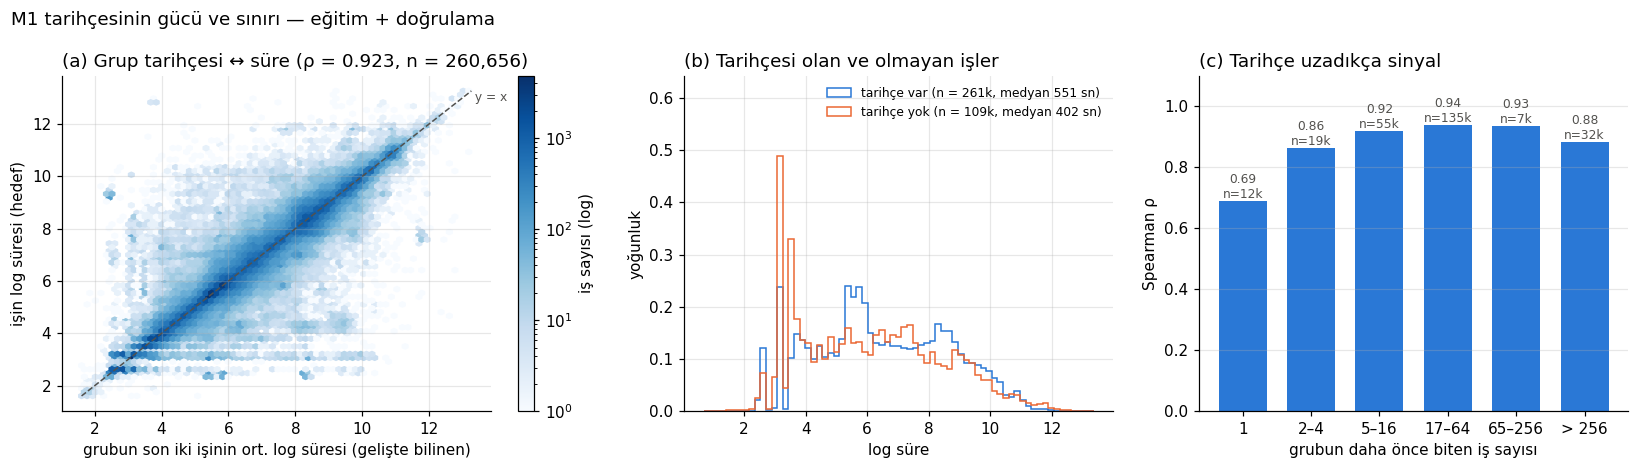

grp_rt_n      n   rho
       1  11999 0.688
     2–4  19414 0.863
    5–16  55374 0.918
   17–64 135153 0.940
  65–256   6751 0.934
   > 256  31965 0.883


In [ ]:
# F17: strength and limit of M1 history — group history vs run time (train + validation)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

BLUE, ORANGE, INK2 = '#2a78d6', '#eb6834', '#52514e'
h = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'grp_rt_n', 'grp_rt_last2'])
H = E[['job_name', 'run_time']].merge(h, on='job_name')
H['y'] = np.log1p(H.run_time)
has = H.grp_rt_last2.notna()
d = H[has]
rho = spearmanr(d.grp_rt_last2, d.y)[0]
print(f'with group history: {has.sum():,} ({100*has.mean():.1f}%) | Spearman rho = {rho:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={'width_ratios': [1.25, 1, 1]})
ax = axes[0]
hb = ax.hexbin(d.grp_rt_last2, d.y, gridsize=70, bins='log', cmap='Blues', mincnt=1)
lo, hi = np.nanmin([d.y.min(), d.grp_rt_last2.min()]), np.nanmax([d.y.max(), d.grp_rt_last2.max()])
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--')
ax.text(hi, hi, ' y = x', fontsize=8, color=INK2, va='top')
ax.set_xlabel('grubun son iki işinin ort. log süresi (gelişte bilinen)'); ax.set_ylabel('işin log süresi (hedef)')
ax.set_title(f'(a) Grup tarihçesi ↔ süre (ρ = {rho:.3f}, n = {has.sum():,})', loc='left')
fig.colorbar(hb, ax=ax, label='iş sayısı (log)')

ax = axes[1]
bins = np.linspace(H.y.min(), H.y.max(), 70)
for mask, col, name in [(has, BLUE, 'tarihçe var'), (~has, ORANGE, 'tarihçe yok')]:
    ax.hist(H.y[mask], bins=bins, density=True, histtype='step', lw=2, color=col,
            label=f'{name} (n = {mask.sum()/1000:.0f}k, medyan {np.expm1(H.y[mask].median()):.0f} sn)')
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
ax.set_xlabel('log süre'); ax.set_ylabel('yoğunluk'); ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('(b) Tarihçesi olan ve olmayan işler', loc='left')

ax = axes[2]
edges = [0, 1, 4, 16, 64, 256, np.inf]
labels = ['1', '2–4', '5–16', '17–64', '65–256', '> 256']
d = d.assign(b=pd.cut(d.grp_rt_n, edges, labels=labels))
rows = [(lab, len(g), spearmanr(g.grp_rt_last2, g.y)[0]) for lab, g in d.groupby('b', observed=True) if len(g) > 50]
bars = ax.bar([r[0] for r in rows], [r[2] for r in rows], color=BLUE, width=0.7)
for b_, r in zip(bars, rows):
    ax.text(b_.get_x() + b_.get_width() / 2, r[2], f"{r[2]:.2f}\nn={r[1]/1000:.0f}k" if r[1] >= 1000 else f"{r[2]:.2f}\nn={r[1]}", ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_ylim(0, 1.1); ax.set_xlabel('grubun daha önce biten iş sayısı'); ax.set_ylabel('Spearman ρ')
ax.set_title('(c) Tarihçe uzadıkça sinyal', loc='left'); ax.grid(axis='x', visible=False)

fig.suptitle('M1 tarihçesinin gücü ve sınırı — eğitim + doğrulama', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 17, 'history_signal')
plt.show()
print(pd.DataFrame(rows, columns=['grp_rt_n', 'n', 'rho']).round(3).to_string(index=False))

jobs 358,322 | most common memory request 29.297 GB = 74.0% of jobs
saved F18_request_vs_usage.png


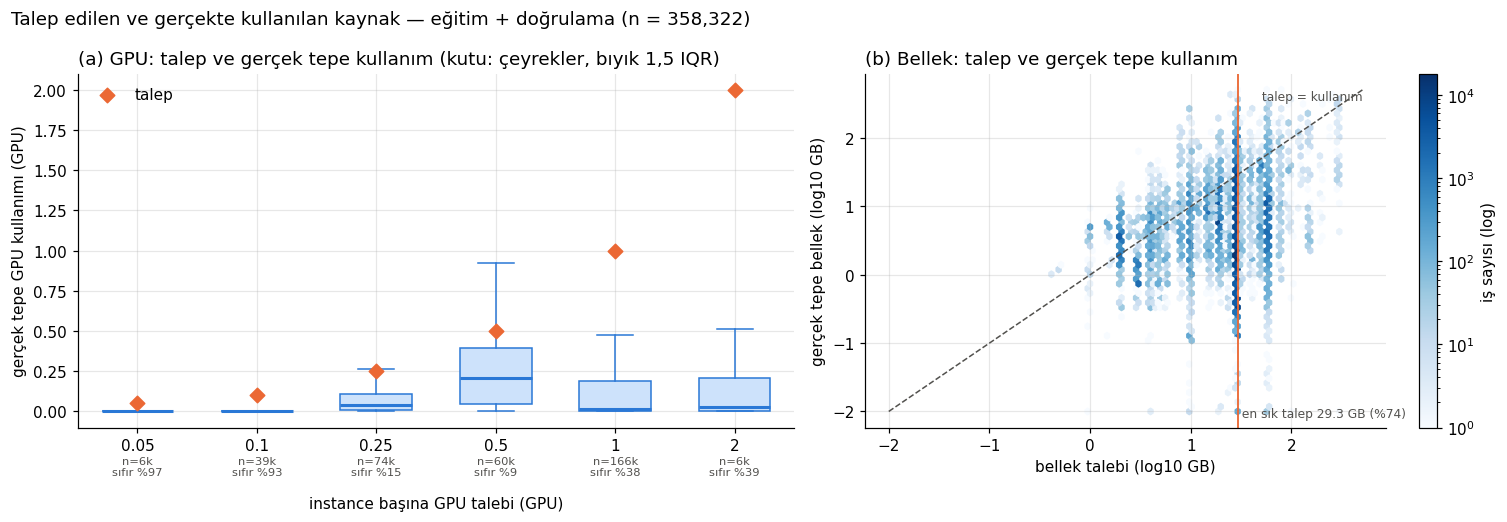

                 group   jobs  median_peak_GB  median_ratio  share_over_request_%
default memory request 265007           3.386         0.116                 7.884
 other memory requests  93315           5.706         0.311                20.207


In [ ]:
# F18: requested vs actually used resources (train + validation, jobs with usage)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, INK2, MUTED = '#2a78d6', '#eb6834', '#52514e', '#898781'
t = pd.read_parquet(PROC / 'targets.parquet',
                    columns=['job_name', 'main_plan_gpu', 'main_plan_mem', 'gpu_util_max', 'max_mem_max'])
t = t[t.job_name.isin(U.job_name)].copy()
t['req_gpu'] = (t.main_plan_gpu / 100).round(2)
t['used_gpu'] = t.gpu_util_max / 100
default_mem = t.main_plan_mem.mode()[0]
is_def = np.isclose(t.main_plan_mem, default_mem)
print(f'jobs {len(t):,} | most common memory request {default_mem:.3f} GB = {100*is_def.mean():.1f}% of jobs')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})

# (a) GPU: used GPU per request level (boxes), request marked
ax = axes[0]
levels = t.req_gpu.value_counts().head(6).index.sort_values()
data = [t.loc[t.req_gpu == L, 'used_gpu'].to_numpy() for L in levels]
ax.boxplot(data, positions=range(len(levels)), widths=0.6, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor='#cde2fb', edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.scatter(range(len(levels)), levels, marker='D', s=45, color=ORANGE, zorder=3, label='talep')
for i, (L, x) in enumerate(zip(levels, data)):
    ax.text(i, -0.08, f'n={len(x)/1000:.0f}k\nsıfır %{100*(x == 0).mean():.0f}', ha='center', va='top',
            fontsize=7.5, color=INK2, transform=ax.get_xaxis_transform())
ax.set_xticks(range(len(levels)), [f'{L:g}' for L in levels])
ax.set_xlabel('instance başına GPU talebi (GPU)', labelpad=28); ax.set_ylabel('gerçek tepe GPU kullanımı (GPU)')
ax.legend(frameon=False, loc='upper left')
ax.set_title('(a) GPU: talep ve gerçek tepe kullanım (kutu: çeyrekler, bıyık 1,5 IQR)', loc='left')

# (b) Memory: request vs peak, log-log, default request marked
ax = axes[1]
x = np.log10(t.main_plan_mem.clip(lower=0.1)); y = np.log10(t.max_mem_max.clip(lower=0.01))
hb = ax.hexbin(x, y, gridsize=60, bins='log', cmap='Blues', mincnt=1)
lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls='--'); ax.text(hi, hi, ' talep = kullanım', fontsize=8, color=INK2, va='top', ha='right')
ax.axvline(np.log10(default_mem), color=ORANGE, lw=1.2)
ax.text(np.log10(default_mem), 0.03, f' en sık talep {default_mem:.1f} GB (%{100*is_def.mean():.0f})',
        transform=ax.get_xaxis_transform(), fontsize=8, color=INK2)
ax.set_xlabel('bellek talebi (log10 GB)'); ax.set_ylabel('gerçek tepe bellek (log10 GB)')
ax.set_title('(b) Bellek: talep ve gerçek tepe kullanım', loc='left')
fig.colorbar(hb, ax=ax, label='iş sayısı (log)')

fig.suptitle(f'Talep edilen ve gerçekte kullanılan kaynak — eğitim + doğrulama (n = {len(t):,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 18, 'request_vs_usage')
plt.show()

s = pd.DataFrame({
    'group': ['default memory request', 'other memory requests'],
    'jobs': [is_def.sum(), (~is_def).sum()],
    'median_peak_GB': [t.max_mem_max[is_def].median(), t.max_mem_max[~is_def].median()],
    'median_ratio': [(t.max_mem_max / t.main_plan_mem)[is_def].median(), (t.max_mem_max / t.main_plan_mem)[~is_def].median()],
    'share_over_request_%': [100 * (t.max_mem_max > t.main_plan_mem)[is_def].mean(), 100 * (t.max_mem_max > t.main_plan_mem)[~is_def].mean()]})
print(s.round(3).to_string(index=False))

Spearman correlations between targets:
              log_run_time  gpu_ratio  mem_ratio  gpu_zero
log_run_time         1.000      0.356      0.648    -0.334
gpu_ratio            0.356      1.000      0.365    -0.844
mem_ratio            0.648      0.365      1.000    -0.327
gpu_zero            -0.334     -0.844     -0.327     1.000
saved F23_target_relations.png


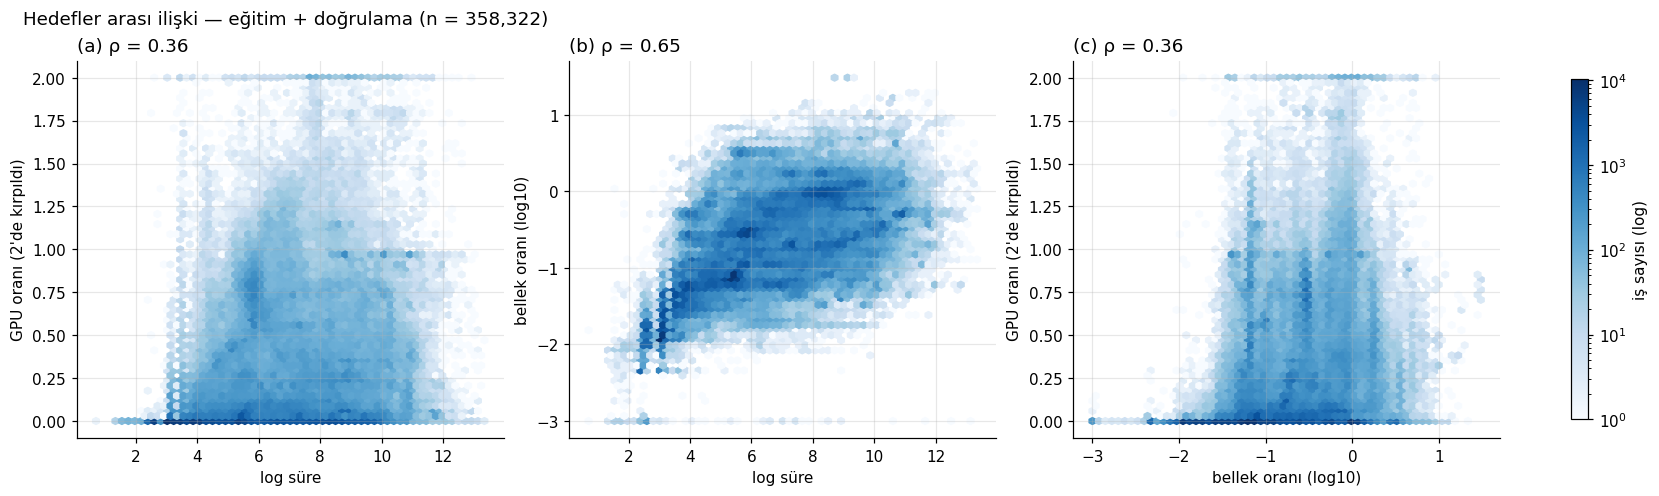


run time (seconds) by GPU-zero status:
                  count    25%    50%     75%
GPU used       233155.0  243.0  878.0  4770.0
GPU ratio = 0  125167.0   32.0  122.0  1695.0


In [ ]:
# F23: relations between the three targets (train + validation, jobs with usage) — why multi-task
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

INK2 = '#52514e'
y = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'log_run_time', 'gpu_ratio', 'mem_ratio'])
y = y[y.job_name.isin(U.job_name)].copy()
y['gpu_zero'] = (y.gpu_ratio == 0).astype(float)
y['log_mem'] = np.log10(y.mem_ratio.clip(lower=1e-3))
cols = ['log_run_time', 'gpu_ratio', 'mem_ratio', 'gpu_zero']
R = y[cols].corr(method='spearman')
print('Spearman correlations between targets:'); print(R.round(3).to_string())
R.to_csv(DRIVE / 'results/tables/midterm_target_correlations.csv')

pairs = [('log_run_time', 'gpu_ratio', 'log süre', 'GPU oranı (2\'de kırpıldı)', lambda s: s.clip(upper=2)),
         ('log_run_time', 'log_mem', 'log süre', 'bellek oranı (log10)', lambda s: s),
         ('log_mem', 'gpu_ratio', 'bellek oranı (log10)', 'GPU oranı (2\'de kırpıldı)', lambda s: s.clip(upper=2))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout='constrained')
for ax, (a, b, la, lb, f), tag in zip(axes, pairs, 'abc'):
    hb = ax.hexbin(y[a], f(y[b]), gridsize=60, bins='log', cmap='Blues', mincnt=1)
    r = spearmanr(y[a], y[b])[0]
    ax.set_xlabel(la); ax.set_ylabel(lb); ax.set_title(f'({tag}) ρ = {r:.2f}', loc='left')
fig.colorbar(hb, ax=axes, label='iş sayısı (log)', shrink=0.9)
fig.suptitle(f'Hedefler arası ilişki — eğitim + doğrulama (n = {len(y):,})', x=0.01, ha='left', fontsize=12)
save_fig(fig, 23, 'target_relations')
plt.show()

# Run time by GPU-zero status: are idle-GPU jobs shorter?
g = y.groupby('gpu_zero').log_run_time.describe(percentiles=[.25, .5, .75])[['count', '25%', '50%', '75%']]
g[['25%', '50%', '75%']] = np.expm1(g[['25%', '50%', '75%']]).round(0)
g.index = ['GPU used', 'GPU ratio = 0']
print('\nrun time (seconds) by GPU-zero status:'); print(g.to_string())

saved F05_m2_channel_distributions.png


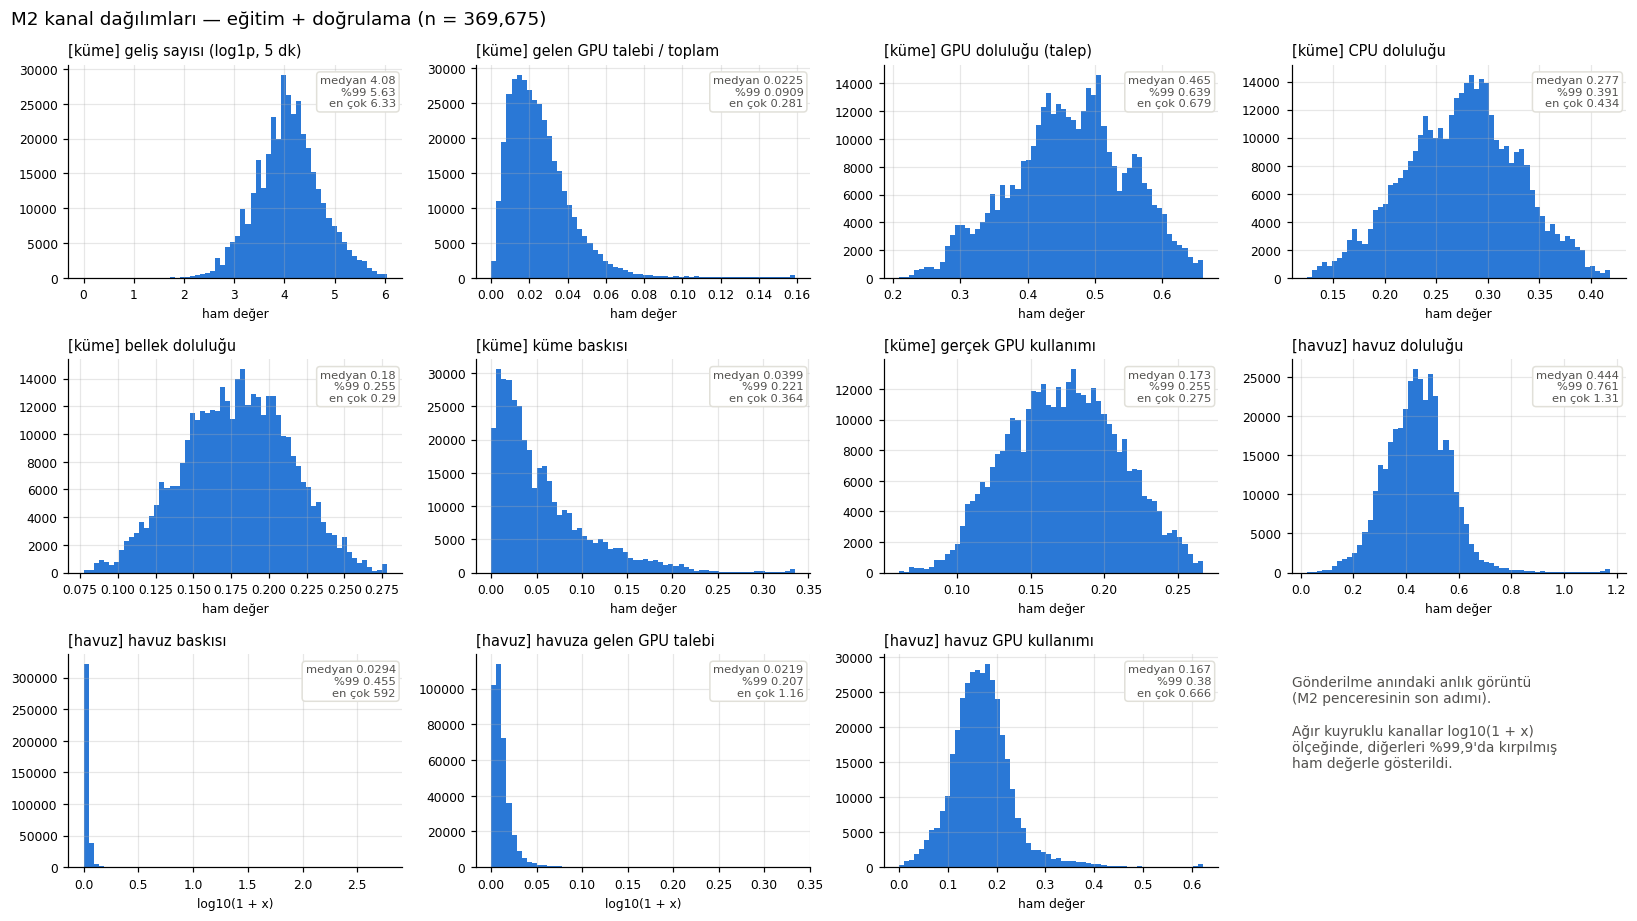

In [ ]:
# F05: M2 snapshot channel distributions at submission (train + validation), raw values
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, INK2 = '#2a78d6', '#52514e'
CH = ['arr_count', 'arr_gpu', 'occ_gpu', 'occ_cpu', 'occ_mem', 'pressure', 'use_gpu',
      'pool_occ', 'pool_pressure', 'pool_arr_gpu', 'pool_use_gpu']
NAMES = {'arr_count': 'geliş sayısı (log1p, 5 dk)', 'arr_gpu': 'gelen GPU talebi / toplam',
         'occ_gpu': 'GPU doluluğu (talep)', 'occ_cpu': 'CPU doluluğu', 'occ_mem': 'bellek doluluğu',
         'pressure': 'küme baskısı', 'use_gpu': 'gerçek GPU kullanımı',
         'pool_occ': 'havuz doluluğu', 'pool_pressure': 'havuz baskısı', 'pool_arr_gpu': 'havuza gelen GPU talebi',
         'pool_use_gpu': 'havuz GPU kullanımı'}
S = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name'] + CH)
S = S[S.job_name.isin(E.job_name)]

fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for ax, c in zip(axes.flat, CH):
    v = S[c].to_numpy()
    q99 = np.quantile(v, 0.99)
    heavy = v.max() > 5 * q99 and v.max() > 1        # very heavy tail -> show log10(1 + x)
    x = np.log10(1 + v) if heavy else np.clip(v, None, np.quantile(v, 0.999))
    ax.hist(x, bins=60, color=BLUE)
    ax.set_title(('[küme] ' if not c.startswith('pool') else '[havuz] ') + NAMES[c], loc='left', fontsize=9.5)
    ax.text(0.98, 0.95, f'medyan {np.median(v):.3g}\n%99 {q99:.3g}\nen çok {v.max():.3g}', transform=ax.transAxes,
            ha='right', va='top', fontsize=7.5, color=INK2, bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#e1e0d9'))
    ax.set_xlabel('log10(1 + x)' if heavy else 'ham değer', fontsize=8); ax.tick_params(labelsize=8)
axes.flat[-1].axis('off')
axes.flat[-1].text(0, 0.9, 'Gönderilme anındaki anlık görüntü\n(M2 penceresinin son adımı).\n\n'
                   'Ağır kuyruklu kanallar log10(1 + x)\nölçeğinde, diğerleri %99,9\'da kırpılmış\nham değerle gösterildi.',
                   va='top', fontsize=9, color=INK2)
fig.suptitle(f'M2 kanal dağılımları — eğitim + doğrulama (n = {len(S):,})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 5, 'm2_channel_distributions')
plt.show()

             jobs  gpu_zero_pct  gpu_ratio_median  mem_ratio_median  coverage_median  n_sensor_median
dur                                                                                                  
< 20 sn      9310        98.829             0.000             0.013              1.0              1.0
20–60 sn    53343        74.793             0.000             0.031              1.0              1.0
1–5 dk      83546        31.482             0.028             0.086              1.0              1.0
5–30 dk     91966        20.607             0.140             0.283              1.0              1.0
30 dk–2 sa  64671        31.223             0.077             0.554              1.0              1.0
2–12 sa     47656        21.641             0.159             0.484              1.0              1.0
> 12 sa      7830         3.972             0.218             0.514              1.0              1.0
saved F12_label_quality_by_duration.png


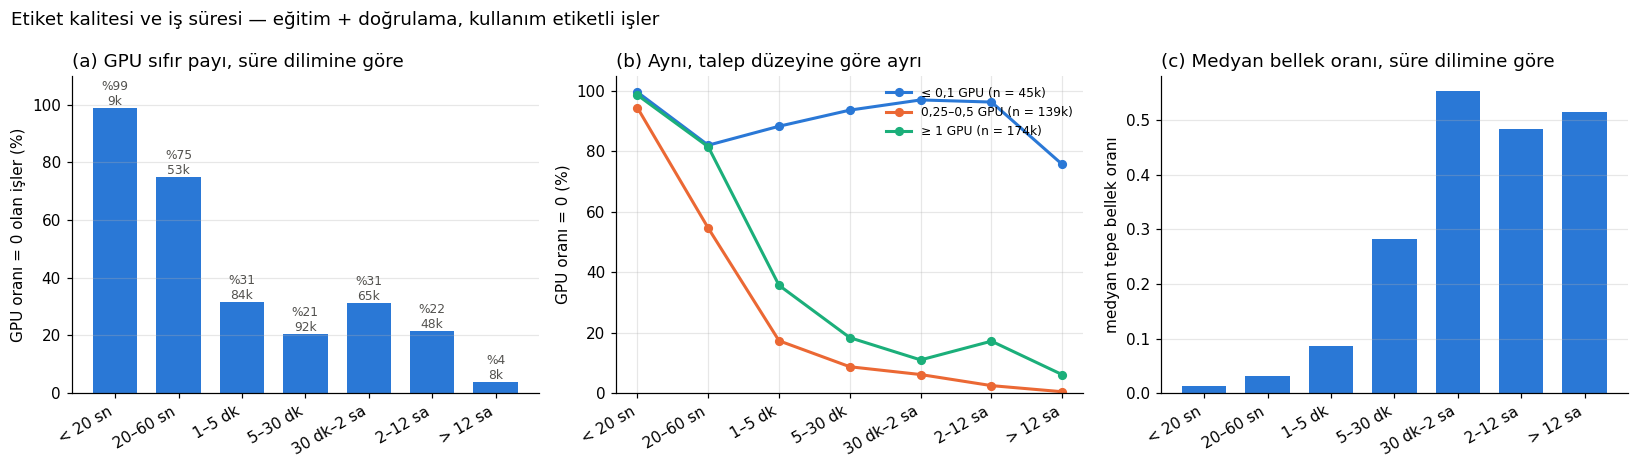

In [ ]:
# F12 (part 1): label quality vs run time — is "GPU ratio = 0" real idleness or a short-job measurement artefact?
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, INK2 = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
q = pd.read_parquet(PROC / 'targets.parquet',
                    columns=['job_name', 'run_time', 'gpu_ratio', 'mem_ratio', 'main_plan_gpu', 'n_sensor', 'usage_coverage'])
q = q[q.job_name.isin(U.job_name)].copy()
edges = [0, 20, 60, 300, 1800, 7200, 43200, np.inf]
labels = ['< 20 sn', '20–60 sn', '1–5 dk', '5–30 dk', '30 dk–2 sa', '2–12 sa', '> 12 sa']
q['dur'] = pd.cut(q.run_time, edges, labels=labels, right=False)
q['req'] = pd.cut(q.main_plan_gpu / 100, [0, 0.1, 0.5, np.inf], labels=['≤ 0,1 GPU', '0,25–0,5 GPU', '≥ 1 GPU'])
q['zero'] = q.gpu_ratio == 0

T = (q.groupby('dur', observed=True)
       .agg(jobs=('job_name', 'size'), gpu_zero_pct=('zero', 'mean'), gpu_ratio_median=('gpu_ratio', 'median'),
            mem_ratio_median=('mem_ratio', 'median'), coverage_median=('usage_coverage', 'median'),
            n_sensor_median=('n_sensor', 'median')))
T['gpu_zero_pct'] *= 100
print(T.round(3).to_string())
T.to_csv(DRIVE / 'results/tables/midterm_label_quality_by_duration.csv')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
x = np.arange(len(T))
ax = axes[0]
bars = ax.bar(x, T.gpu_zero_pct, color=BLUE, width=0.7)
for b_, v, n in zip(bars, T.gpu_zero_pct, T.jobs):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f'%{v:.0f}\n{n/1000:.0f}k', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_xticks(x, T.index, rotation=30, ha='right'); ax.set_ylim(0, 110); ax.set_ylabel('GPU oranı = 0 olan işler (%)')
ax.set_title('(a) GPU sıfır payı, süre dilimine göre', loc='left'); ax.grid(axis='x', visible=False)

ax = axes[1]
for (name, g), col in zip(q.groupby('req', observed=True), [BLUE, ORANGE, AQUA]):
    s = 100 * g.groupby('dur', observed=True).zero.mean().reindex(labels)
    ax.plot(range(len(labels)), s.values, color=col, lw=2, marker='o', ms=5, label=f'{name} (n = {len(g)/1000:.0f}k)')
ax.set_xticks(range(len(labels)), labels, rotation=30, ha='right'); ax.set_ylim(0, 105)
ax.set_ylabel('GPU oranı = 0 (%)'); ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('(b) Aynı, talep düzeyine göre ayrı', loc='left')

ax = axes[2]
ax.bar(x, T.mem_ratio_median, color=BLUE, width=0.7)
ax.set_xticks(x, T.index, rotation=30, ha='right'); ax.set_ylabel('medyan tepe bellek oranı')
ax.set_title('(c) Medyan bellek oranı, süre dilimine göre', loc='left'); ax.grid(axis='x', visible=False)

fig.suptitle('Etiket kalitesi ve iş süresi — eğitim + doğrulama, kullanım etiketli işler', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 12, 'label_quality_by_duration')
plt.show()

usage-labelled jobs: 358,322
  gpu_ratio: > 1 11,532 (3.22%) | > 10 20 (0.006%) | max 70.0
  mem_ratio: > 1 39,749 (11.09%) | > 10 94 (0.026%) | max 30.4
GPU ratio > 10: request levels {0.05: 12, 0.01: 8} | max used GPU 0.95 (all labelled jobs: 7.22)
mem ratio > 10: median request 9.77 GB, median peak 288.00 GB, max peak 505.9 GB
  GPU ratio > 10: users 5 | top user share 35% | top-10 users (whole set) 0%
  mem ratio > 10: users 11 | top user share 37% | top-10 users (whole set) 0%

example jobs (rule: largest ratios):
           rule    job_name  req_gpu  used_gpu  gpu_ratio  main_plan_mem  max_mem_max  mem_ratio  main_inst_num  run_time
top-5 gpu_ratio af2c91af29…     0.01     0.700     70.000          3.906        1.967      0.503            1.0      20.0
top-5 gpu_ratio 37ebf23ed4…     0.01     0.601     60.067          3.906        2.149      0.550            1.0      64.0
top-5 gpu_ratio 91d9a012e8…     0.01     0.555     55.538          3.906        2.337      0.598            1

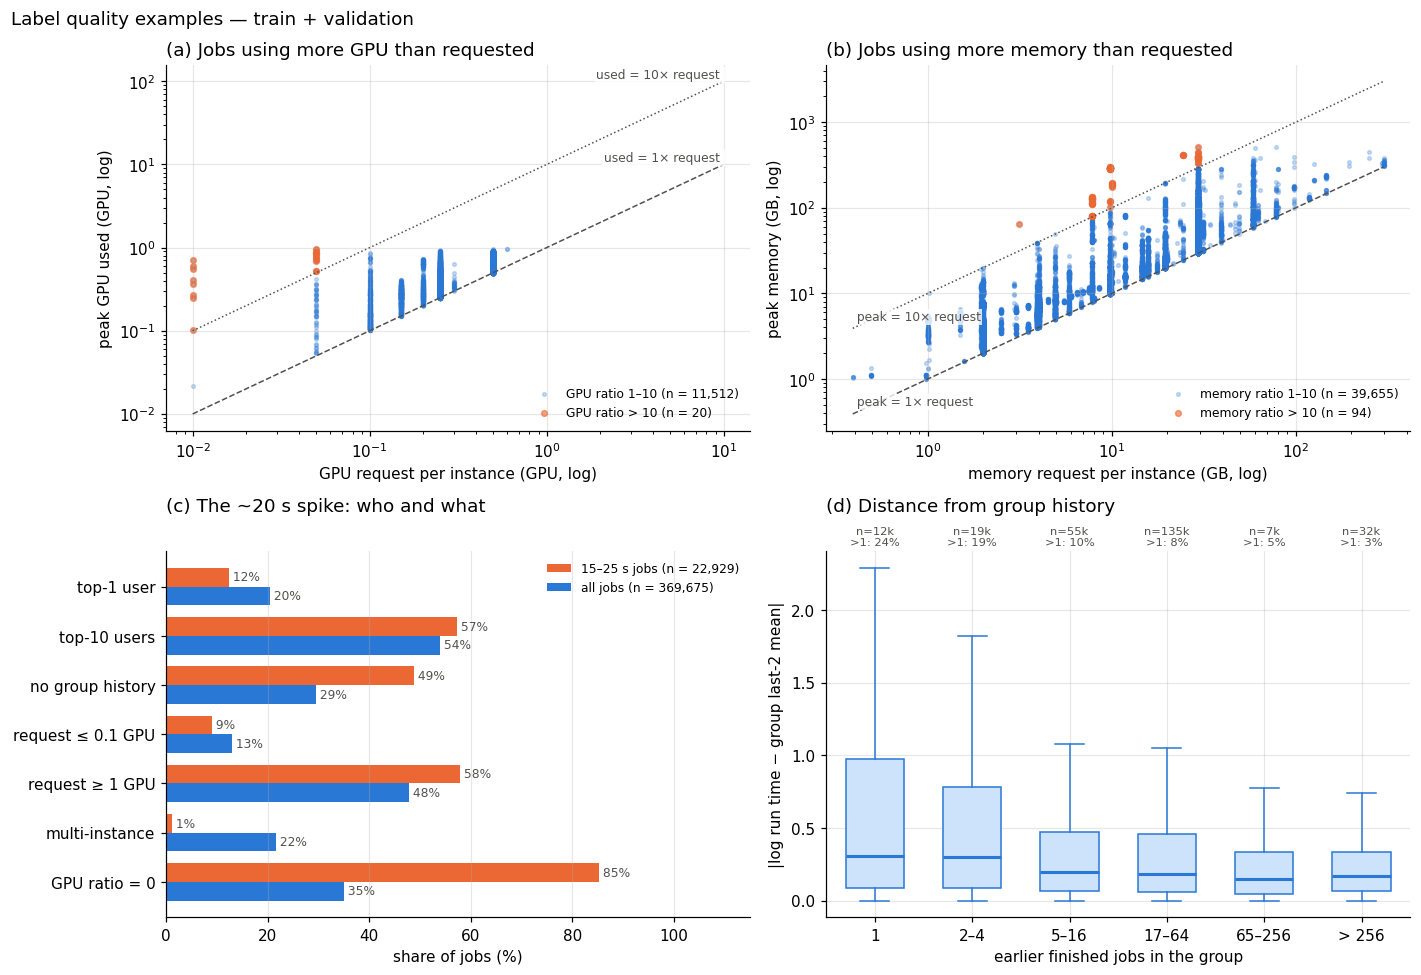

saved midterm_label_quality_examples.csv, midterm_label_quality_extreme_jobs.csv


In [10]:
# F12 (part 2): label quality examples — extreme ratios, the ~20 s spike, and history in giant groups
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, INK2, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#52514e', '#898781'
q = pd.read_parquet(PROC / 'targets.parquet',
                    columns=['job_name', 'run_time', 'gpu_ratio', 'mem_ratio', 'main_plan_gpu', 'main_plan_mem',
                             'gpu_util_max', 'max_mem_max', 'main_inst_num'])
m = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'user', 'grp_rt_n', 'grp_rt_last2'])
A = E[['job_name']].merge(q, on='job_name').merge(m, on='job_name')     # train + val, not purged
A['req_gpu'] = (A.main_plan_gpu / 100).round(2)
A['used_gpu'] = A.gpu_util_max / 100
A['has_usage'] = A.job_name.isin(U.job_name)
L = A[A.has_usage]                                                      # jobs with usage labels
top10 = A.user.astype(str).value_counts().head(10).index

# ---- 1) Extreme labels: how many, from which request levels, and are they physically plausible?
ext_gpu, ext_mem = L[L.gpu_ratio > 10], L[L.mem_ratio > 10]
print(f'usage-labelled jobs: {len(L):,}')
for name, s, col in [('gpu_ratio', L.gpu_ratio, 'used_gpu'), ('mem_ratio', L.mem_ratio, 'max_mem_max')]:
    print(f'  {name}: > 1 {int((s > 1).sum()):,} ({100*(s > 1).mean():.2f}%) | > 10 {int((s > 10).sum()):,} '
          f'({100*(s > 10).mean():.3f}%) | max {s.max():.1f}')
print(f'GPU ratio > 10: request levels {ext_gpu.req_gpu.value_counts().head(5).to_dict()} | '
      f'max used GPU {ext_gpu.used_gpu.max():.2f} (all labelled jobs: {L.used_gpu.max():.2f})')
print(f'mem ratio > 10: median request {ext_mem.main_plan_mem.median():.2f} GB, '
      f'median peak {ext_mem.max_mem_max.median():.2f} GB, max peak {ext_mem.max_mem_max.max():.1f} GB')
for name, d in [('GPU ratio > 10', ext_gpu), ('mem ratio > 10', ext_mem)]:
    if len(d):
        print(f'  {name}: users {d.user.nunique()} | top user share {100*d.user.value_counts(normalize=True).iloc[0]:.0f}% '
              f'| top-10 users (whole set) {100*d.user.astype(str).isin(top10).mean():.0f}%')

# Example jobs by rule: the 5 largest ratios of each kind (descriptive, train + val only)
ex = pd.concat([L.nlargest(5, 'gpu_ratio').assign(rule='top-5 gpu_ratio'),
                L.nlargest(5, 'mem_ratio').assign(rule='top-5 mem_ratio')])
ex = ex[['rule', 'job_name', 'req_gpu', 'used_gpu', 'gpu_ratio', 'main_plan_mem', 'max_mem_max', 'mem_ratio',
         'main_inst_num', 'run_time']].round(3)
ex['job_name'] = ex.job_name.str[:10] + '…'
print('\nexample jobs (rule: largest ratios):'); print(ex.to_string(index=False))

# ---- 2) The ~20 s spike: who submits these jobs and what do they request?
S = A[A.run_time.between(15, 25)]
def profile(d, lab):
    du = d[d.has_usage]
    return pd.Series({'top-1 user': (d.user.astype(str) == top10[0]).mean(),
                      'top-10 users': d.user.astype(str).isin(top10).mean(),
                      'no group history': (d.grp_rt_n.fillna(0) == 0).mean(),
                      'request ≤ 0.1 GPU': (d.req_gpu <= 0.1).mean(),
                      'request ≥ 1 GPU': (d.req_gpu >= 1).mean(),
                      'multi-instance': (d.main_inst_num > 1).mean(),
                      'GPU ratio = 0': (du.gpu_ratio == 0).mean()}, name=lab)
P = pd.concat([profile(S, f'15–25 s jobs (n = {len(S):,})'), profile(A, f'all jobs (n = {len(A):,})')], axis=1)
print('\n~20 s jobs vs all jobs (shares):'); print((100 * P).round(1).to_string())
s_users = S.user.astype(str).value_counts(normalize=True)
print(f'~20 s jobs: {S.user.nunique()} users, top user {100*s_users.iloc[0]:.0f}%, top 5 {100*s_users.head(5).sum():.0f}%')

# ---- 3) Giant groups: how far is the job from its group's recent history?
H = A[A.grp_rt_last2.notna()].copy()
H['abs_err'] = (np.log1p(H.run_time) - H.grp_rt_last2).abs()
edges = [0, 1, 4, 16, 64, 256, np.inf]
blabs = ['1', '2–4', '5–16', '17–64', '65–256', '> 256']
H['b'] = pd.cut(H.grp_rt_n, edges, labels=blabs)
G = H.groupby('b', observed=True).abs_err.describe(percentiles=[.25, .5, .75, .9])
G['share_err_gt_1'] = H.groupby('b', observed=True).abs_err.apply(lambda s: (s > 1).mean())
print('\n|log run time − group last-2 mean| by group history length:'); print(G.round(3).to_string())

# ---- Figure
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0, 0]                                     # (a) GPU: request vs used for ratio > 1
o = L[L.gpu_ratio > 1]
ax.scatter(o.req_gpu, o.used_gpu, s=6, alpha=0.25, color=BLUE, label=f'GPU ratio 1–10 (n = {int((o.gpu_ratio <= 10).sum()):,})')
ax.scatter(ext_gpu.req_gpu, ext_gpu.used_gpu, s=14, alpha=0.6, color=ORANGE, label=f'GPU ratio > 10 (n = {len(ext_gpu):,})')
xx = np.array([0.01, 10])
for k, ls in [(1, '--'), (10, ':')]:
    ax.plot(xx, k * xx, color=INK2, lw=1, ls=ls)
    ax.text(xx[1], k * xx[1], f'used = {k}× request ', fontsize=8, color=INK2, ha='right', va='bottom',
            bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('GPU request per instance (GPU, log)'); ax.set_ylabel('peak GPU used (GPU, log)')
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('(a) Jobs using more GPU than requested', loc='left')

ax = axes[0, 1]                                     # (b) memory: request vs peak for ratio > 1
o = L[L.mem_ratio > 1]
ax.scatter(o.main_plan_mem, o.max_mem_max, s=6, alpha=0.25, color=BLUE, label=f'memory ratio 1–10 (n = {int((o.mem_ratio <= 10).sum()):,})')
ax.scatter(ext_mem.main_plan_mem, ext_mem.max_mem_max, s=14, alpha=0.6, color=ORANGE, label=f'memory ratio > 10 (n = {len(ext_mem):,})')
xx = np.array([max(0.1, L.main_plan_mem.min()), L.main_plan_mem.max()])
for k, ls in [(1, '--'), (10, ':')]:
    ax.plot(xx, k * xx, color=INK2, lw=1, ls=ls)
    ax.text(xx[0], k * xx[0] * 1.15, f' peak = {k}× request', fontsize=8, color=INK2, ha='left', va='bottom',
            bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('memory request per instance (GB, log)'); ax.set_ylabel('peak memory (GB, log)')
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('(b) Jobs using more memory than requested', loc='left')

ax = axes[1, 0]                                     # (c) ~20 s profile vs all jobs
y = np.arange(len(P))
h = 0.38
ax.barh(y - h / 2, 100 * P.iloc[:, 0], height=h, color=ORANGE, label=P.columns[0])
ax.barh(y + h / 2, 100 * P.iloc[:, 1], height=h, color=BLUE, label=P.columns[1])
for i, (a, b) in enumerate(zip(P.iloc[:, 0], P.iloc[:, 1])):
    ax.text(100 * a, i - h / 2, f' {100*a:.0f}%', va='center', fontsize=8, color=INK2)
    ax.text(100 * b, i + h / 2, f' {100*b:.0f}%', va='center', fontsize=8, color=INK2)
ax.set_yticks(y, P.index); ax.invert_yaxis(); ax.set_xlim(0, 115); ax.set_xlabel('share of jobs (%)')
ax.legend(frameon=False, fontsize=8, loc='upper right'); ax.grid(axis='y', visible=False)
ax.set_title('(c) The ~20 s spike: who and what', loc='left', pad=26)

ax = axes[1, 1]                                     # (d) error of group history by history length
data = [H.loc[H.b == b_, 'abs_err'].to_numpy() for b_ in blabs]
ax.boxplot(data, positions=range(len(blabs)), widths=0.6, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor='#cde2fb', edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
for i, d in enumerate(data):
    ax.text(i, 1.01, f'n={len(d)/1000:.0f}k\n>1: {100*(d > 1).mean():.0f}%' if len(d) >= 1000 else f'n={len(d)}\n>1: {100*(d > 1).mean():.0f}%',
            ha='center', va='bottom', fontsize=7.5, color=INK2, transform=ax.get_xaxis_transform())
ax.set_xticks(range(len(blabs)), blabs)
ax.set_xlabel('earlier finished jobs in the group'); ax.set_ylabel('|log run time − group last-2 mean|')
ax.set_title('(d) Distance from group history', loc='left', pad=26)

fig.suptitle('Label quality examples — train + validation', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 12, 'label_quality_examples')
plt.show()

out = pd.concat([(100 * P).round(2).rename_axis('metric').reset_index().assign(table='spike_20s_profile_pct'),
                 G.round(4).rename_axis('history_len').reset_index().assign(table='history_abs_err')], ignore_index=True)
out.to_csv(DRIVE / 'results/tables/midterm_label_quality_examples.csv', index=False)
ex.to_csv(DRIVE / 'results/tables/midterm_label_quality_extreme_jobs.csv', index=False)
print('saved midterm_label_quality_examples.csv, midterm_label_quality_extreme_jobs.csv')

In [11]:
# A5 check: target correlations with and without jobs shorter than 60 s (train + validation, usage labels)
import numpy as np, pandas as pd

y = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'run_time', 'log_run_time', 'gpu_ratio', 'mem_ratio'])
y = y[y.job_name.isin(U.job_name)].copy()
y['gpu_zero'] = (y.gpu_ratio == 0).astype(float)
cols = ['log_run_time', 'gpu_ratio', 'mem_ratio', 'gpu_zero']
pairs = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:]]
rows = []
for name, d in [('all', y), ('run_time >= 60 s', y[y.run_time >= 60]), ('run_time >= 30 min', y[y.run_time >= 1800])]:
    R = d[cols].corr(method='spearman')
    rows.append(pd.Series({f'{a} ~ {b}': R.loc[a, b] for a, b in pairs}, name=f'{name} (n = {len(d):,})'))
C = pd.DataFrame(rows).T
print(C.round(3).to_string())
C.to_csv(DRIVE / 'results/tables/midterm_target_correlations_by_duration.csv')
print('saved midterm_target_correlations_by_duration.csv')

                          all (n = 358,322)  run_time >= 60 s (n = 295,669)  run_time >= 30 min (n = 120,157)
log_run_time ~ gpu_ratio              0.356                           0.132                             0.134
log_run_time ~ mem_ratio              0.648                           0.450                             0.075
log_run_time ~ gpu_zero              -0.334                          -0.081                            -0.145
gpu_ratio ~ mem_ratio                 0.365                           0.174                            -0.030
gpu_ratio ~ gpu_zero                 -0.844                          -0.764                            -0.763
mem_ratio ~ gpu_zero                 -0.327                          -0.096                             0.124
saved midterm_target_correlations_by_duration.csv


run time skewness: raw 11.49 | log1p 0.17 | train mean/std of log1p 6.399 / 2.199

42 numeric M1 columns | log1p applied to 22 | missing indicators 15 | binary columns left out of the plot 5
            feature  log1p  missing_%  skew_raw  skew_model_input  max_abs_z
         usr_rt_std  False       0.20     -0.78             -0.78       4.87
        usr_rt_mean  False       0.11     -0.40             -0.40       4.52
            dow_cos  False       0.00     -0.19             -0.19       1.58
           hour_sin  False       0.00     -0.17             -0.17       1.50
           hour_cos  False       0.00     -0.01             -0.01       1.45
       grp_rt_last2  False      29.49      0.10              0.12       3.15
        grp_rt_last  False      29.49      0.11              0.12       3.07
        grp_rt_mean  False      29.49      0.11              0.12       3.11
       usr_rt_last2  False       0.11      0.12              0.12       3.32
        usr_rt_last  False       0.11  

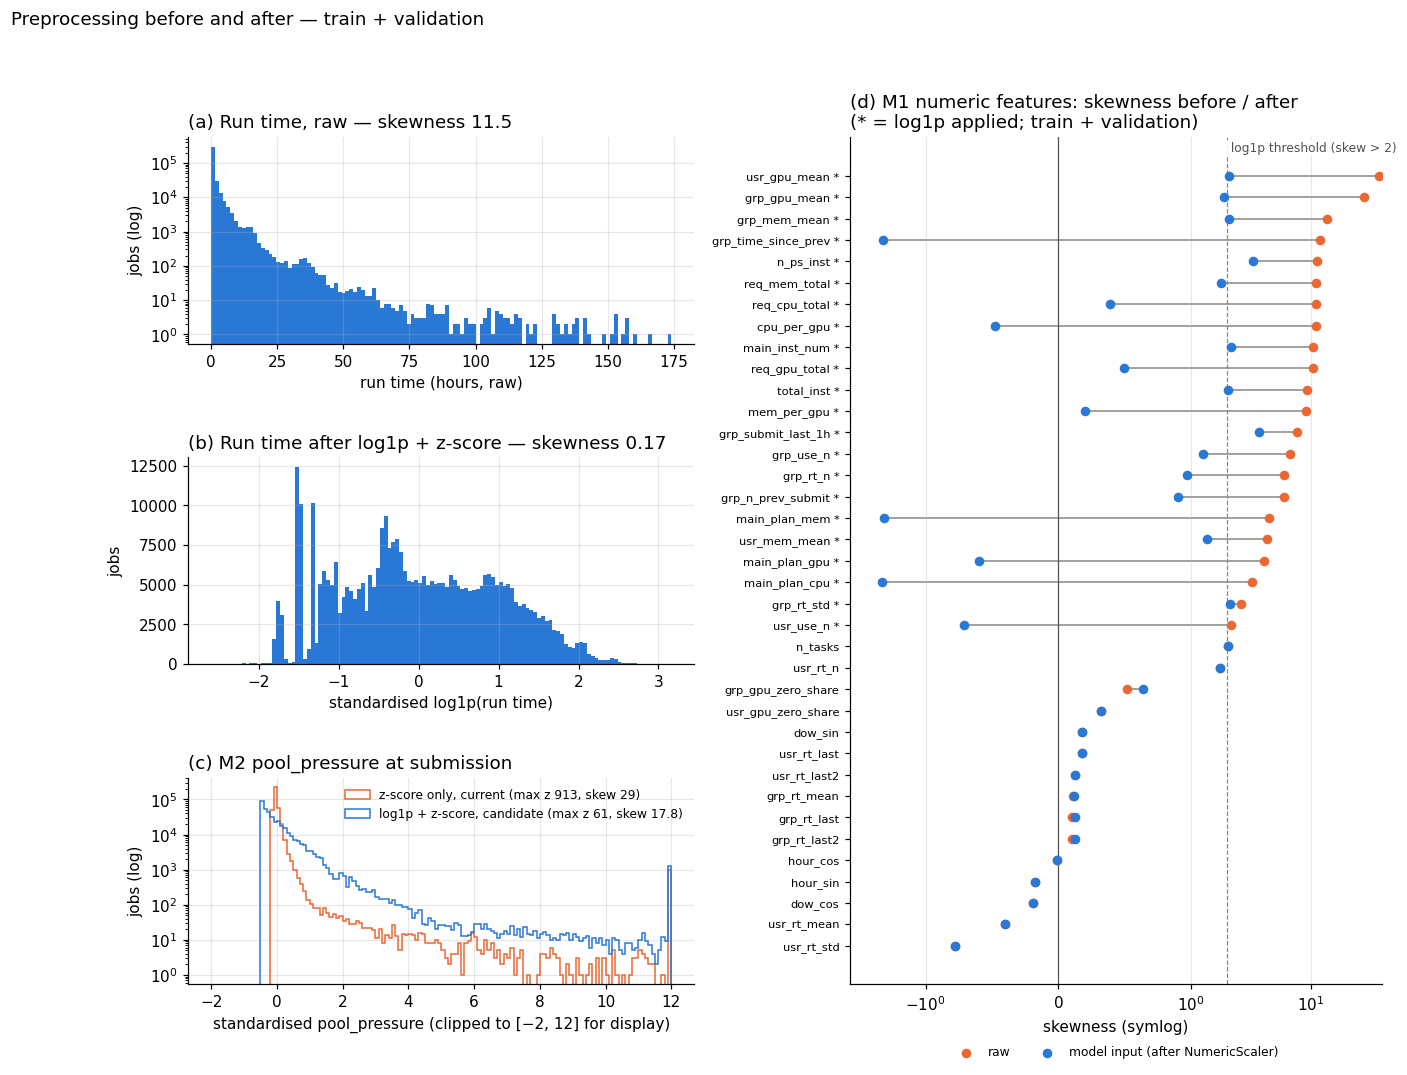

In [12]:
# F10: before–after preprocessing — run-time target, M1 numeric features (NumericScaler), M2 pool_pressure
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from tevzi.models.preprocess import NumericScaler
from tevzi.features.m1 import CATEGORICAL

BLUE, ORANGE, INK2, MUTED = '#2a78d6', '#eb6834', '#52514e', '#898781'
tg = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'period', 'run_time'])
tg = tg[tg.job_name.isin(E.job_name)]
m1 = pd.read_parquet(PROC / 'm1_features.parquet')
m1 = m1[m1.job_name.isin(E.job_name)].merge(tg[['job_name', 'period']], on='job_name')
sp = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'pool_pressure'])
sp = sp[sp.job_name.isin(E.job_name)].merge(tg[['job_name', 'period']], on='job_name')
trn = m1.period.eq('train')                              # scalers are fitted on train only (as in Stage 3)

# 1) Target: run time raw -> log1p -> standardised with train mean / std
rt = tg.run_time.to_numpy(float)
lrt = np.log1p(rt)
mu, sd = lrt[tg.period.eq('train').to_numpy()].mean(), lrt[tg.period.eq('train').to_numpy()].std()
z_rt = (lrt - mu) / sd
print(f'run time skewness: raw {skew(rt):.2f} | log1p {skew(lrt):.2f} | train mean/std of log1p {mu:.3f} / {sd:.3f}')

# 2) M1 numeric features through the Stage 3 NumericScaler (fit on train, measured on train + val)
num_cols = [c for c in m1.columns if c not in ('job_name', 'period', *CATEGORICAL)]
scaler = NumericScaler.fit(m1[trn], num_cols)
Z = scaler.transform(m1)
rows = []
for c in num_cols:
    x = m1[c].to_numpy(dtype=float)
    f = x[np.isfinite(x)]
    if np.unique(f).size <= 2:                           # binary columns: skewness is not meaningful
        continue
    rows.append({'feature': c, 'log1p': c in scaler.log_cols, 'missing_%': 100 * np.isnan(x).mean(),
                 'skew_raw': skew(f), 'skew_model_input': skew(Z[c].to_numpy(float)),
                 'max_abs_z': float(np.abs(Z[c]).max())})
S = pd.DataFrame(rows).sort_values('skew_raw')
print(f'\n{len(num_cols)} numeric M1 columns | log1p applied to {len(scaler.log_cols)} | '
      f'missing indicators {len(scaler.na_cols)} | binary columns left out of the plot {len(num_cols) - len(S)}')
print(S.round(2).to_string(index=False))
S.round(4).to_csv(DRIVE / 'results/tables/midterm_preprocessing_effect.csv', index=False)

# 3) M2 pool_pressure: current fit_scaler (z-score only) vs log1p + z-score (candidate for 3.6)
p = sp.pool_pressure.to_numpy(float)
pt = sp.period.eq('train').to_numpy()
z_only = (p - p[pt].mean()) / p[pt].std()
lp = np.log1p(p)
z_log = (lp - lp[pt].mean()) / lp[pt].std()
for name, z in [('z only (current)', z_only), ('log1p + z (candidate)', z_log)]:
    print(f'pool_pressure {name:22s}: skew {skew(z):7.2f} | max z {z.max():6.1f} | '
          f'share within ±0.1 of the median {100*np.mean(np.abs(z - np.median(z)) < 0.1):.1f}%')

# ---- Figure
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(3, 2, width_ratios=[1, 1.05], hspace=0.55, wspace=0.3)

ax = fig.add_subplot(gs[0, 0])                           # (a) raw run time
ax.hist(rt / 3600, bins=120, color=BLUE)
ax.set_yscale('log'); ax.set_xlabel('run time (hours, raw)'); ax.set_ylabel('jobs (log)')
ax.set_title(f'(a) Run time, raw — skewness {skew(rt):.1f}', loc='left')

ax = fig.add_subplot(gs[1, 0])                           # (b) log1p + z
ax.hist(z_rt, bins=120, color=BLUE)
ax.set_xlabel('standardised log1p(run time)'); ax.set_ylabel('jobs')
ax.set_title(f'(b) Run time after log1p + z-score — skewness {skew(lrt):.2f}', loc='left')

ax = fig.add_subplot(gs[2, 0])                           # (c) M2 pool_pressure
bins = np.linspace(-2, 12, 141)
ax.hist(np.clip(z_only, -2, 12), bins=bins, histtype='step', lw=2, color=ORANGE,
        label=f'z-score only, current (max z {z_only.max():.0f}, skew {skew(z_only):.0f})')
ax.hist(np.clip(z_log, -2, 12), bins=bins, histtype='step', lw=2, color=BLUE,
        label=f'log1p + z-score, candidate (max z {z_log.max():.0f}, skew {skew(z_log):.1f})')
ax.set_yscale('log'); ax.set_xlabel('standardised pool_pressure (clipped to [−2, 12] for display)')
ax.set_ylabel('jobs (log)'); ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('(c) M2 pool_pressure at submission', loc='left')

ax = fig.add_subplot(gs[:, 1])                           # (d) skewness before / after for M1 features
y = np.arange(len(S))
for i, r in enumerate(S.itertuples()):
    ax.plot([r.skew_raw, r.skew_model_input], [i, i], color=MUTED, lw=1, zorder=1)
ax.scatter(S.skew_raw, y, s=28, color=ORANGE, zorder=2, label='raw')
ax.scatter(S.skew_model_input, y, s=28, color=BLUE, zorder=3, label='model input (after NumericScaler)')
labels = [f'{f} *' if lg else f for f, lg in zip(S.feature, S.log1p)]
ax.set_yticks(y, labels, fontsize=7.5)
ax.set_xscale('symlog', linthresh=1)
ax.axvline(0, color=INK2, lw=0.8); ax.axvline(2, color=MUTED, lw=0.8, ls='--')
ax.text(2, 0.995, ' log1p threshold (skew > 2)', transform=ax.get_xaxis_transform(), fontsize=8, color=INK2, va='top',
        bbox=dict(fc='white', ec='none', alpha=0.85, pad=1))
ax.set_xlabel('skewness (symlog)'); ax.grid(axis='y', visible=False)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2)
ax.set_title('(d) M1 numeric features: skewness before / after\n(* = log1p applied; train + validation)', loc='left')

fig.suptitle('Preprocessing before and after — train + validation', x=0.01, y=0.995, ha='left', fontsize=12)
save_fig(fig, 10, 'preprocessing_before_after')
plt.show()

Failed jobs that started: 256,555 | recorded end: 9.9% | median recorded run 162 s (used for the rest)
check: recomputed pressure matches the stored grid: True

train + validation grid points:
 channel  median_terminated_only  median_with_failed  pearson  spearman
 occ_gpu                   0.452               0.518    0.972     0.974
pressure                   0.038               0.110    0.866     0.872

run starts in train + validation:
                        jobs  gpu_hours  jobs_%  gpu_hours_%
Terminated (in M2)    381194  2429953.1    78.1         87.9
Failed, recorded end   13742   327007.4     2.8         11.8
Failed, imputed end    93165     8703.5    19.1          0.3
saved F11_failed_load_before_after.png


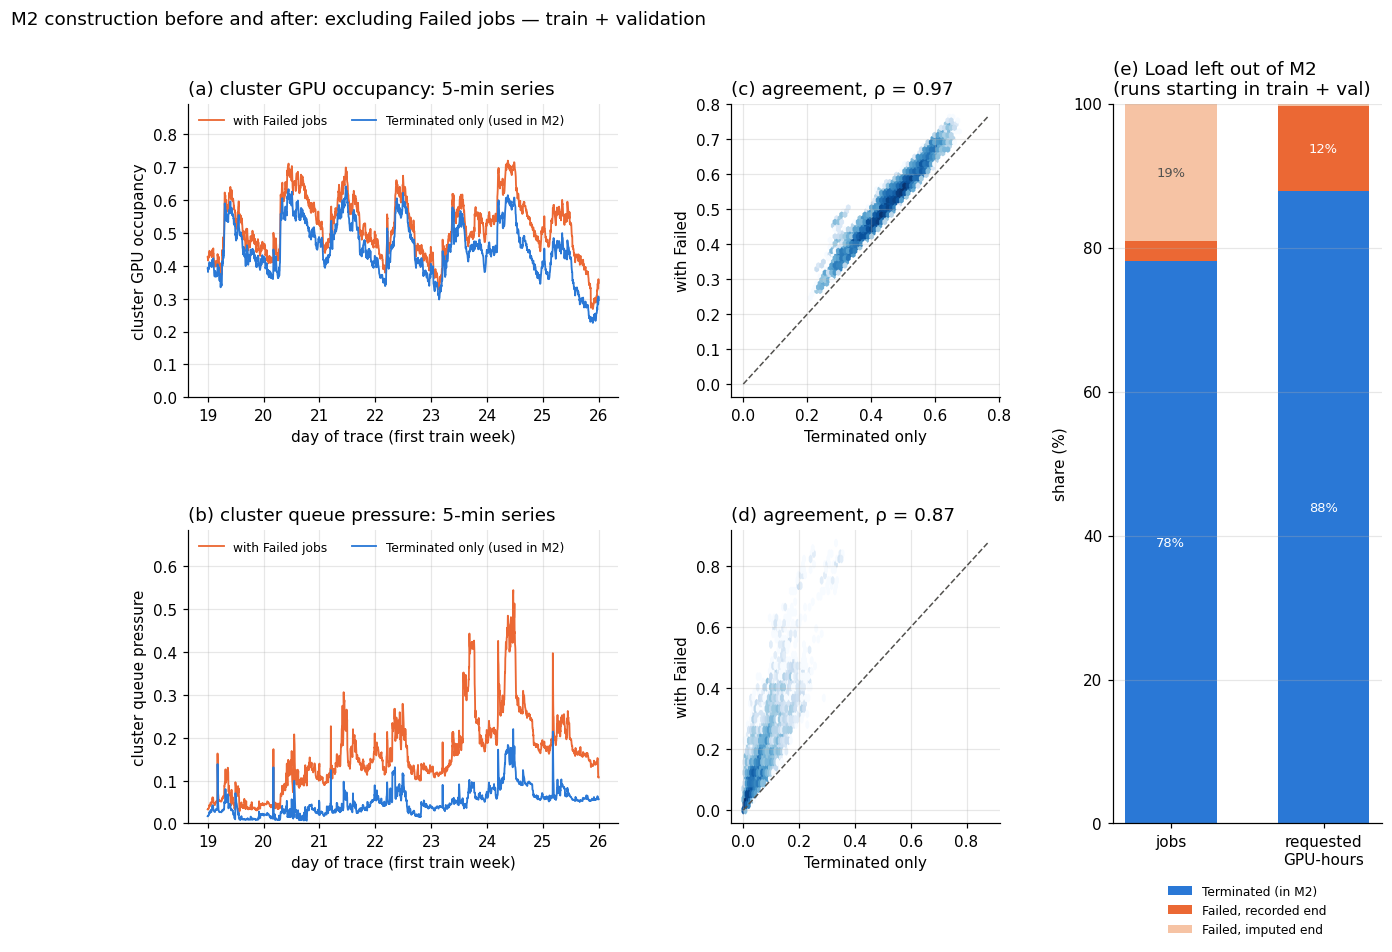

In [13]:
# F11: before–after M2 construction — Terminated-only load (used) vs adding Failed jobs; information loss
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from tevzi.features.m2 import Level, capacities
from tevzi.data.split import T0, DAY

BLUE, ORANGE, AQUA, INK2, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#52514e', '#898781'
jf = pd.read_parquet(PROC / 'jobs_flags.parquet',
                     columns=['job_name', 'status', 'submit_time', 'first_start', 'end_time', 'req_gpu_total', 'm2_occupancy'])
grid = pd.read_parquet(PROC / 'm2_grid.parquet', columns=['t', 'occ_gpu', 'pressure'])
cap = capacities(INTERIM)['gpu']
t = grid.t.to_numpy()
rows_tv = (t >= T0 + 19 * DAY) & (t < T0 + 52 * DAY)       # train + validation grid points

# Variant: add Failed jobs that started; end = recorded end if valid, else start + median known run
fail = jf[jf.status.eq('Failed') & jf.first_start.notna()].copy()
fail['end_known'] = fail.end_time.where(fail.end_time > fail.first_start)
med_run = (fail.end_known - fail.first_start).median()
fail['end_used'] = fail.end_known.fillna(fail.first_start + med_run)
fail['gpu'] = fail.req_gpu_total.fillna(0)
base = jf[jf.m2_occupancy.astype(bool)]
print(f'Failed jobs that started: {len(fail):,} | recorded end: {100*fail.end_known.notna().mean():.1f}% | '
      f'median recorded run {med_run:.0f} s (used for the rest)')

occ_D = grid.occ_gpu.to_numpy()
queue_D = Level(base.submit_time, base.first_start, base.req_gpu_total.fillna(0))(t)
press_D = queue_D / np.maximum(cap - occ_D * cap, 100.0)
occ_F = occ_D + Level(fail.first_start, fail.end_used, fail.gpu)(t) / cap
press_F = (queue_D + Level(fail.submit_time, fail.first_start, fail.gpu)(t)) / np.maximum(cap - occ_F * cap, 100.0)
print('check: recomputed pressure matches the stored grid:', bool(np.allclose(press_D, grid.pressure.to_numpy(), atol=1e-6)))

rows = []
for ch, d, v in [('occ_gpu', occ_D, occ_F), ('pressure', press_D, press_F)]:
    d_, v_ = d[rows_tv], v[rows_tv]
    rows.append({'channel': ch, 'median_terminated_only': np.median(d_), 'median_with_failed': np.median(v_),
                 'pearson': np.corrcoef(d_, v_)[0, 1], 'spearman': spearmanr(d_, v_)[0]})
R = pd.DataFrame(rows)
print('\ntrain + validation grid points:'); print(R.round(3).to_string(index=False))

# Information loss: jobs and requested GPU-hours whose run starts in train + validation
lo, hi = T0 + 19 * DAY, T0 + 52 * DAY
def gpu_hours(d, end):
    return (d.req_gpu_total.fillna(0) / 100 * (d[end] - d.first_start) / 3600).clip(lower=0)
b = base[base.first_start.between(lo, hi)].assign(end_used=lambda d: d.end_time)
f = fail[fail.first_start.between(lo, hi)]
parts = pd.DataFrame({
    'jobs': [len(b), int(f.end_known.notna().sum()), int(f.end_known.isna().sum())],
    'gpu_hours': [gpu_hours(b, 'end_used').sum(), gpu_hours(f[f.end_known.notna()], 'end_used').sum(),
                  gpu_hours(f[f.end_known.isna()], 'end_used').sum()]},
    index=['Terminated (in M2)', 'Failed, recorded end', 'Failed, imputed end'])
parts['jobs_%'] = 100 * parts.jobs / parts.jobs.sum()
parts['gpu_hours_%'] = 100 * parts.gpu_hours / parts.gpu_hours.sum()
print('\nrun starts in train + validation:'); print(parts.round(1).to_string())
pd.concat([R.assign(table='channel_agreement'),
           parts.reset_index(names='set').assign(table='information_loss')]).round(4) \
  .to_csv(DRIVE / 'results/tables/midterm_failed_load_sensitivity.csv', index=False)

# ---- Figure
fig = plt.figure(figsize=(14, 8.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 1, 1], hspace=0.45, wspace=0.35)
wk = (t >= T0 + 19 * DAY) & (t < T0 + 26 * DAY)           # rule: first full week of the train period
days = (t[wk] - T0) / DAY
for i, (ch, d, v, lab) in enumerate([('occ_gpu', occ_D, occ_F, 'cluster GPU occupancy'),
                                     ('pressure', press_D, press_F, 'cluster queue pressure')]):
    ax = fig.add_subplot(gs[i, 0])
    ax.plot(days, v[wk], color=ORANGE, lw=1.2, label='with Failed jobs')
    ax.plot(days, d[wk], color=BLUE, lw=1.2, label='Terminated only (used in M2)')
    ax.set_ylabel(lab); ax.set_xlabel('day of trace (first train week)')
    ax.legend(frameon=False, fontsize=8, loc='upper left', ncol=2)
    ax.set_title(f'({"ab"[i]}) {lab}: 5-min series', loc='left')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)

    ax = fig.add_subplot(gs[i, 1])
    r = R.iloc[i]
    ax.hexbin(d[rows_tv], v[rows_tv], gridsize=45, bins='log', cmap='Blues', mincnt=1)
    m = max(d[rows_tv].max(), v[rows_tv].max())
    ax.plot([0, m], [0, m], color=INK2, lw=1, ls='--')
    ax.set_xlabel('Terminated only'); ax.set_ylabel('with Failed')
    ax.set_title(f'({"cd"[i]}) agreement, ρ = {r.spearman:.2f}', loc='left')

ax = fig.add_subplot(gs[:, 2])                            # (e) information loss
x = np.arange(2)
cols = [BLUE, ORANGE, '#f6c3a4']
bottom = np.zeros(2)
for (name, row), c in zip(parts.iterrows(), cols):
    vals = np.array([row['jobs_%'], row['gpu_hours_%']])
    ax.bar(x, vals, bottom=bottom, color=c, width=0.6, label=name)
    for xi, (v_, b_) in enumerate(zip(vals, bottom)):
        if v_ >= 3:
            ax.text(xi, b_ + v_ / 2, f'{v_:.0f}%', ha='center', va='center', fontsize=8.5,
                    color='white' if c != '#f6c3a4' else INK2)
    bottom += vals
ax.set_xticks(x, ['jobs', 'requested\nGPU-hours']); ax.set_ylim(0, 100); ax.set_ylabel('share (%)')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.07))
ax.grid(axis='x', visible=False)
ax.set_title('(e) Load left out of M2\n(runs starting in train + val)', loc='left')

fig.suptitle('M2 construction before and after: excluding Failed jobs — train + validation', x=0.01, ha='left', fontsize=12)
save_fig(fig, 11, 'failed_load_before_after')
plt.show()

jobs: 369,675 | pools: {'ALL': 226783, 'T4': 101106, 'P100': 27170, 'V100': 9257, 'V100M32': 5359}

Spearman rho with wait time:
              set      n  rho_pool_pressure  rho_cluster_pressure  median_wait_s  q90_wait_s
pooled (all jobs) 369675              0.230                 0.054            7.0       119.0
              ALL 226783              0.064                 0.064           10.0       115.0
               T4 101106              0.099                 0.068            3.0         4.0
             P100  27170              0.172                 0.136           11.0       780.2
             V100   9257              0.365                 0.287           42.0      4294.4
          V100M32   5359              0.362                 0.283          107.0      5894.4

by within-pool pressure quintile:
pool_key  q     n  pressure_median  wait_median  wait_q90  share_wait_gt_10min
     ALL  1 45357            0.008          9.0      45.0                0.031
     ALL  2 45356          

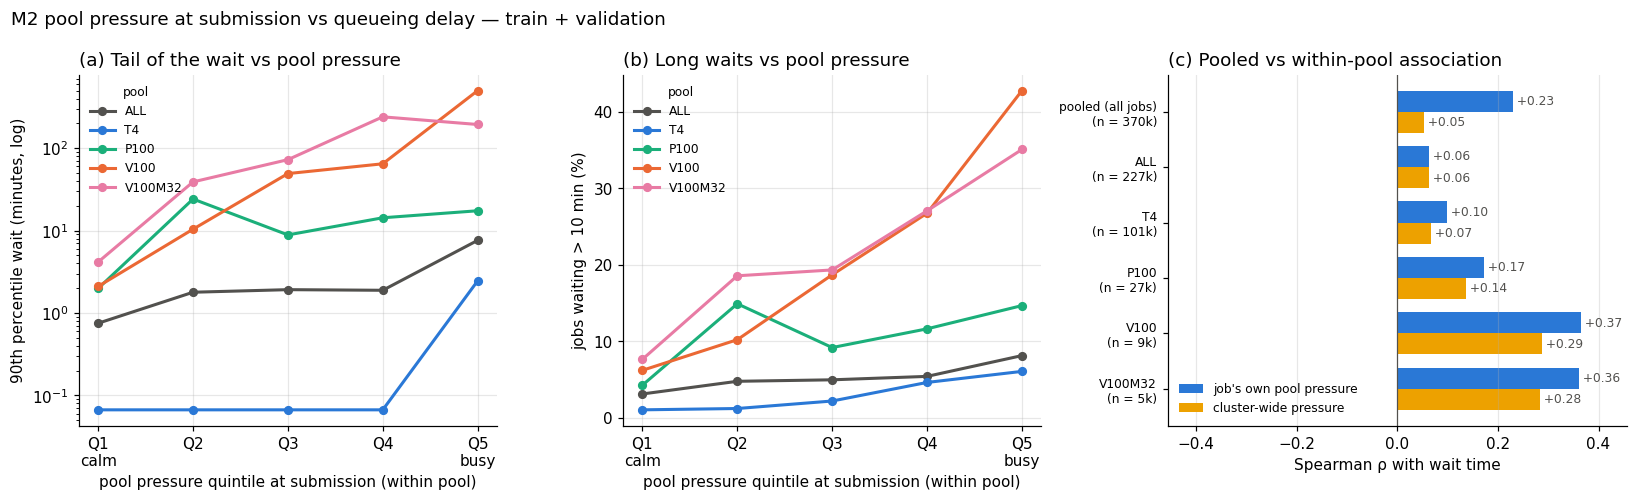

In [14]:
# F08: cross-modal #2 — pool pressure at submission (M2) vs queueing delay, per pool and pooled (Simpson check)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

POOLS = ['ALL', 'T4', 'P100', 'V100', 'V100M32']
PCOL = dict(zip(POOLS, ['#52514e', '#2a78d6', '#1baf7a', '#eb6834', '#e87ba4']))
INK2, MUTED = '#52514e', '#898781'
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'pool_key', 'pressure', 'pool_pressure'])
w = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'wait_time'])
D = E[['job_name']].merge(sn, on='job_name').merge(w, on='job_name')
print(f'jobs: {len(D):,} | pools: {D.pool_key.value_counts().to_dict()}')

# Correlations within each pool and pooled; cluster pressure vs the job's own pool pressure
rows = []
for name, g in [('pooled (all jobs)', D)] + [(p, D[D.pool_key == p]) for p in POOLS]:
    rows.append({'set': name, 'n': len(g),
                 'rho_pool_pressure': spearmanr(g.pool_pressure, g.wait_time)[0],
                 'rho_cluster_pressure': spearmanr(g.pressure, g.wait_time)[0],
                 'median_wait_s': g.wait_time.median(), 'q90_wait_s': g.wait_time.quantile(0.9)})
C = pd.DataFrame(rows)
print('\nSpearman rho with wait time:'); print(C.round(3).to_string(index=False))

# Within-pool pressure quintiles: median wait and share waiting > 10 min
D['q'] = D.groupby('pool_key').pool_pressure.transform(lambda s: pd.qcut(s.rank(method='first'), 5, labels=False)) + 1
Q = (D.groupby(['pool_key', 'q'])
       .agg(n=('wait_time', 'size'), pressure_median=('pool_pressure', 'median'), wait_median=('wait_time', 'median'),
            wait_q90=('wait_time', lambda s: s.quantile(0.9)), share_wait_gt_10min=('wait_time', lambda s: (s > 600).mean()))
       .reset_index())
print('\nby within-pool pressure quintile:'); print(Q.round(3).to_string(index=False))
pd.concat([C.assign(table='correlations'), Q.assign(table='quintiles')]).round(4) \
  .to_csv(DRIVE / 'results/tables/midterm_pressure_wait.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1, 1, 1.1]})
for p in POOLS:
    g = Q[Q.pool_key == p]
    axes[0].plot(g.q, g.wait_q90 / 60, color=PCOL[p], lw=2, marker='o', ms=5, label=p)
    axes[1].plot(g.q, 100 * g.share_wait_gt_10min, color=PCOL[p], lw=2, marker='o', ms=5, label=p)
axes[0].set_yscale('log'); axes[0].set_ylabel('90th percentile wait (minutes, log)')
axes[0].set_title('(a) Tail of the wait vs pool pressure', loc='left')
axes[1].set_ylabel('jobs waiting > 10 min (%)')
axes[1].set_title('(b) Long waits vs pool pressure', loc='left')
for ax in axes[:2]:
    ax.set_xticks(range(1, 6), ['Q1\ncalm', 'Q2', 'Q3', 'Q4', 'Q5\nbusy'])
    ax.set_xlabel('pool pressure quintile at submission (within pool)')
    ax.legend(frameon=False, fontsize=8, title='pool', title_fontsize=8, loc='upper left')

ax = axes[2]
y = np.arange(len(C))
h = 0.38
ax.barh(y - h / 2, C.rho_pool_pressure, height=h, color='#2a78d6', label="job's own pool pressure")
ax.barh(y + h / 2, C.rho_cluster_pressure, height=h, color='#eda100', label='cluster-wide pressure')
for i, r in C.iterrows():
    for off, v in [(-h / 2, r.rho_pool_pressure), (h / 2, r.rho_cluster_pressure)]:
        ax.text(v, i + off, f' {v:+.2f}' if v >= 0 else f'{v:+.2f} ', va='center', ha='left' if v >= 0 else 'right',
                fontsize=8, color=INK2)
ax.set_yticks(y, [f'{s}\n(n = {n/1000:.0f}k)' if n >= 1000 else f'{s}\n(n = {n})' for s, n in zip(C.set, C.n)], fontsize=8)
ax.invert_yaxis(); ax.axvline(0, color=INK2, lw=0.8)
lim = 1.25 * np.abs(C[['rho_pool_pressure', 'rho_cluster_pressure']].to_numpy()).max()
ax.set_xlim(-lim, lim); ax.set_xlabel('Spearman ρ with wait time')
ax.legend(frameon=False, fontsize=8, loc='lower left'); ax.grid(axis='y', visible=False)
ax.set_title('(c) Pooled vs within-pool association', loc='left')

fig.suptitle('M2 pool pressure at submission vs queueing delay — train + validation', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 8, 'pressure_vs_wait')
plt.show()

machine_metric rows 2,009,423 | used 1,767,929 (88.0%)
machine_metric coverage starts on day 24 (first day above half its median; rule from notebook 03)
M2 channel             period  points  spearman_5min  pearson_daily  days
   use_gpu all train+val days    9504          0.288         -0.334    33
   use_gpu         days >= 24    8064          0.666          0.392    28
   occ_gpu all train+val days    9504          0.513          0.067    33
   occ_gpu         days >= 24    8064          0.748          0.578    28
saved F09_m2_vs_machine_metric.png


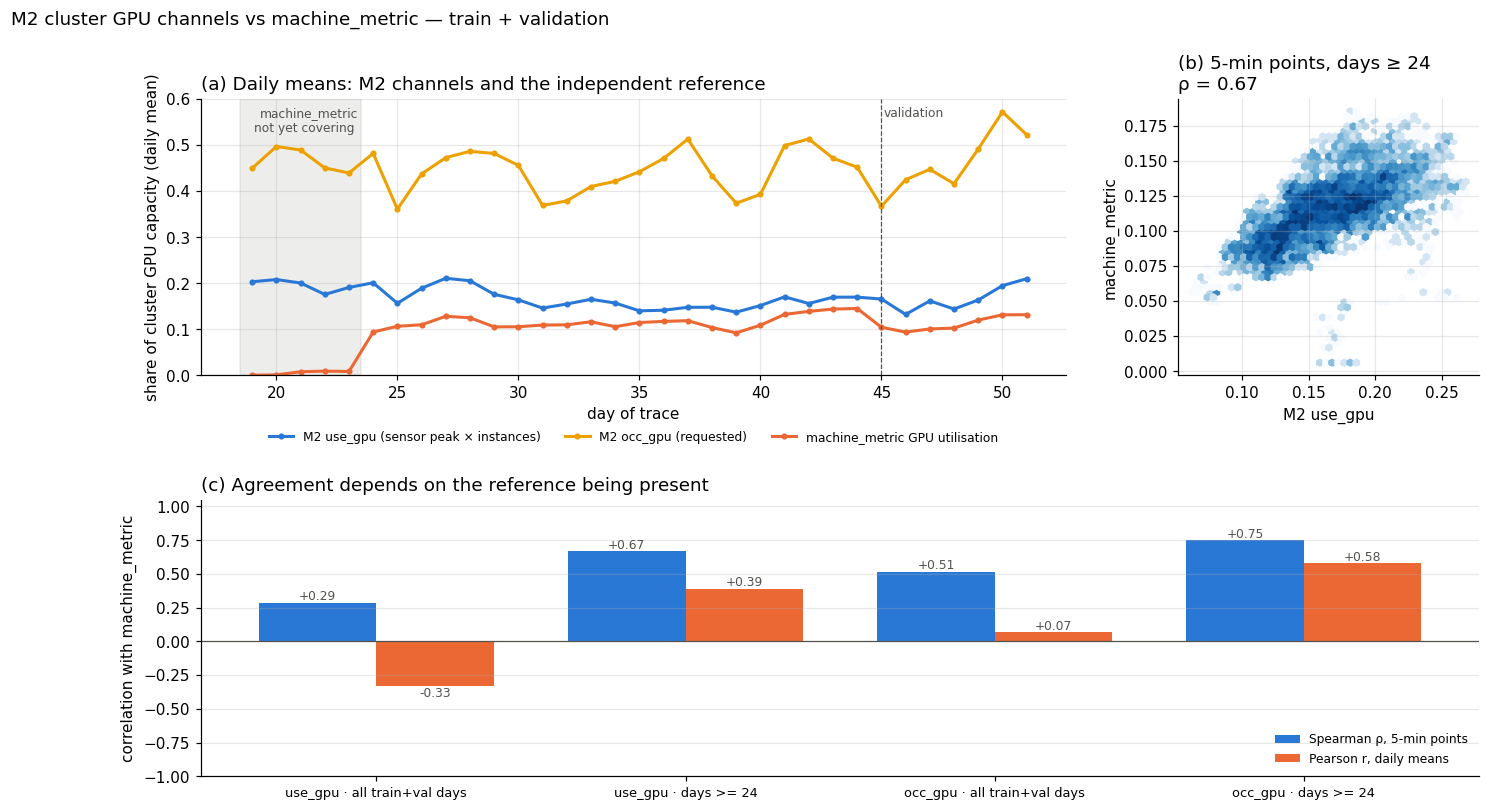

In [15]:
# F09: cross-modal #3 — M2 cluster GPU channels vs an independent source (machine_metric GPU utilisation)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from tevzi.features.m2 import Level, capacities
from tevzi.data.loader import load_table
from tevzi.data.split import T0, DAY

BLUE, ORANGE, YELLOW, INK2, MUTED = '#2a78d6', '#eb6834', '#eda100', '#52514e', '#898781'
grid = pd.read_parquet(PROC / 'm2_grid.parquet', columns=['t', 'occ_gpu', 'use_gpu'])
cap = capacities(INTERIM)['gpu']
mm = load_table('machine_metric', INTERIM, columns=['start_time', 'end_time', 'machine_gpu', 'machine_num_worker'])
n_raw = len(mm)
mm = mm.dropna(subset=['machine_gpu', 'start_time', 'end_time'])
share = mm.machine_gpu / mm.machine_num_worker.fillna(1).clip(lower=1)     # each worker row's share (as in notebook 03)
t = grid.t.to_numpy()
ref = Level(mm.start_time, mm.end_time, share)(t) / cap
print(f'machine_metric rows {n_raw:,} | used {len(mm):,} ({100*len(mm)/n_raw:.1f}%)')
del mm, share

day = (t - T0) / DAY
tv = (day >= 19) & (day < 52)
S = pd.DataFrame({'day': np.floor(day[tv]).astype(int), 'use_gpu': grid.use_gpu.to_numpy()[tv],
                  'occ_gpu': grid.occ_gpu.to_numpy()[tv], 'machine_metric': ref[tv]})
daily = S.groupby('day').mean()
start = int(daily.index[daily.machine_metric > 0.5 * daily.machine_metric.median()].min())
print(f'machine_metric coverage starts on day {start} (first day above half its median; rule from notebook 03)')
ok = S.day >= start
rows = []
for ch in ['use_gpu', 'occ_gpu']:
    for name, m in [('all train+val days', np.ones(len(S), bool)), (f'days >= {start}', ok.to_numpy())]:
        d = S[m]; dd = d.groupby('day').mean()
        rows.append({'M2 channel': ch, 'period': name, 'points': len(d),
                     'spearman_5min': spearmanr(d[ch], d.machine_metric)[0],
                     'pearson_daily': dd[ch].corr(dd.machine_metric), 'days': len(dd)})
R = pd.DataFrame(rows)
print(R.round(3).to_string(index=False))
R.round(4).to_csv(DRIVE / 'results/tables/midterm_m2_vs_machine_metric.csv', index=False)

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 3, width_ratios=[1.5, 1, 1], hspace=0.45, wspace=0.32)

ax = fig.add_subplot(gs[0, :2])                           # (a) daily means, coverage start marked
ax.plot(daily.index, daily.use_gpu, color=BLUE, lw=2, marker='o', ms=3, label='M2 use_gpu (sensor peak × instances)')
ax.plot(daily.index, daily.occ_gpu, color=YELLOW, lw=2, marker='o', ms=3, label='M2 occ_gpu (requested)')
ax.plot(daily.index, daily.machine_metric, color=ORANGE, lw=2, marker='o', ms=3, label='machine_metric GPU utilisation')
ax.axvspan(daily.index.min() - 0.5, start - 0.5, color=MUTED, alpha=0.15)
ax.text(start - 0.6, 0.97, 'machine_metric\nnot yet covering ', transform=ax.get_xaxis_transform(), ha='right', va='top', fontsize=8, color=INK2)
ax.axvline(45, color=INK2, lw=0.8, ls='--'); ax.text(45.1, 0.97, 'validation', transform=ax.get_xaxis_transform(), fontsize=8, color=INK2, va='top')
ax.set_xlabel('day of trace'); ax.set_ylabel('share of cluster GPU capacity (daily mean)')
ax.set_ylim(0, None); ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3)
ax.set_title('(a) Daily means: M2 channels and the independent reference', loc='left')

ax = fig.add_subplot(gs[0, 2])                            # (b) 5-min agreement, covered days
d = S[ok]
ax.hexbin(d.use_gpu, d.machine_metric, gridsize=45, bins='log', cmap='Blues', mincnt=1)
ax.set_xlabel('M2 use_gpu'); ax.set_ylabel('machine_metric')
ax.set_title(f'(b) 5-min points, days ≥ {start}\nρ = {spearmanr(d.use_gpu, d.machine_metric)[0]:.2f}', loc='left')

ax = fig.add_subplot(gs[1, :])                            # (c) correlation summary
lab = [f'{r["M2 channel"]} · {r.period}' for _, r in R.iterrows()]
x = np.arange(len(R)); w_ = 0.38
ax.bar(x - w_ / 2, R.spearman_5min, width=w_, color=BLUE, label='Spearman ρ, 5-min points')
ax.bar(x + w_ / 2, R.pearson_daily, width=w_, color=ORANGE, label='Pearson r, daily means')
for xi, (a, b) in enumerate(zip(R.spearman_5min, R.pearson_daily)):
    for off, v in [(-w_ / 2, a), (w_ / 2, b)]:
        ax.text(xi + off, v, f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=8, color=INK2)
ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(x, lab, fontsize=8.5); ax.set_ylim(-1, 1.05)
ax.set_ylabel('correlation with machine_metric'); ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.grid(axis='x', visible=False)
ax.set_title('(c) Agreement depends on the reference being present', loc='left')

fig.suptitle('M2 cluster GPU channels vs machine_metric — train + validation', x=0.01, ha='left', fontsize=12)
save_fig(fig, 9, 'm2_vs_machine_metric')
plt.show()

jobs 369,675 | busy share 26.1% | with history (run time) 260,656 | usage-labelled >= 60 s 295,669
   pool             target      n    rho  ci_lo  ci_hi  median_busy  median_calm  abs_gt_1_busy_%  abs_gt_1_calm_%  n_busy
    ALL  run time residual 167619  0.033  0.027  0.038        0.000       -0.015           13.316           10.799   43264
    ALL          GPU ratio 182156  0.023  0.018  0.027        0.053        0.048              NaN              NaN   49406
    ALL GPU ratio residual 134896 -0.011 -0.016 -0.005        0.000        0.000              NaN              NaN   35029
     T4  run time residual  68685  0.013  0.006  0.021        0.000        0.000            4.069            3.865   14818
     T4          GPU ratio  77880 -0.013 -0.021 -0.006        0.305        0.216              NaN              NaN   17463
     T4 GPU ratio residual  55204  0.024  0.015  0.033        0.000        0.000              NaN              NaN   12469
   P100  run time residual  15117  0.004

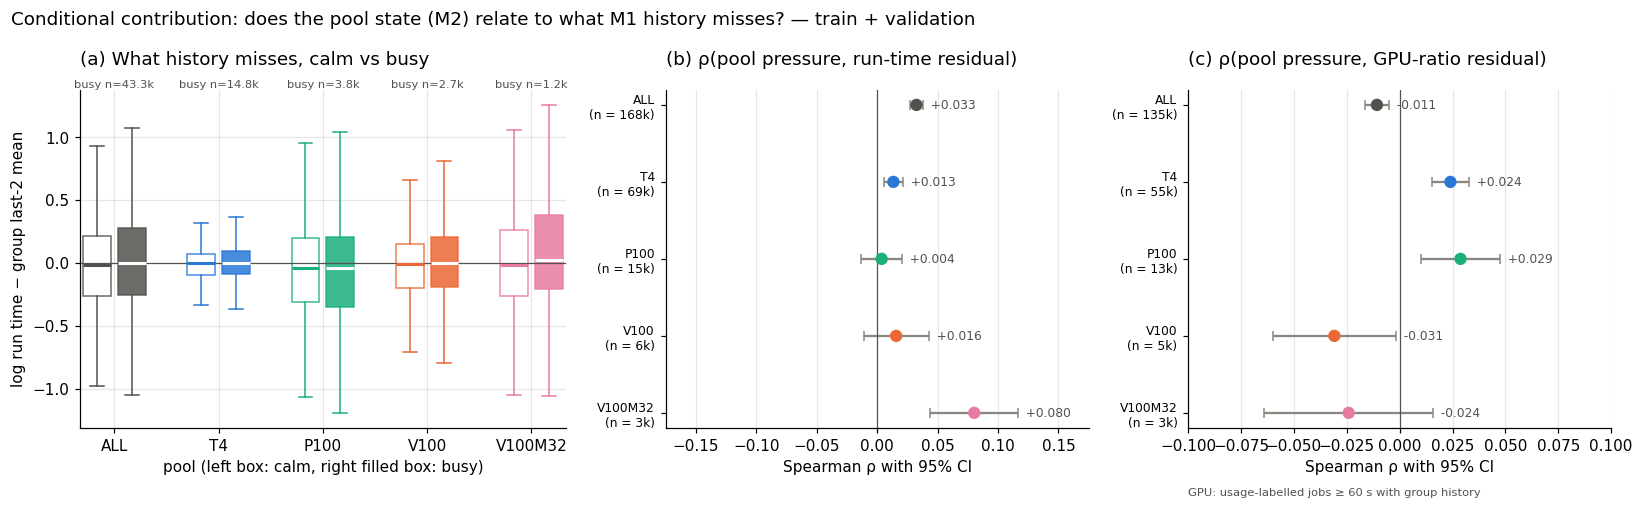

In [16]:
# F22: cross-modal #4 — conditional contribution: what M1 history misses, by pool pressure at submission (M2)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

POOLS = ['ALL', 'T4', 'P100', 'V100', 'V100M32']
PCOL = dict(zip(POOLS, ['#52514e', '#2a78d6', '#1baf7a', '#eb6834', '#e87ba4']))
INK2, MUTED = '#52514e', '#898781'
BUSY = 0.0665                                             # protocol: busy = pool_pressure >= train q75 (12.11)
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'pool_key', 'pool_pressure'])
tg = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'run_time', 'log_run_time', 'gpu_ratio', 'mem_ratio'])
hm = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'grp_rt_last2', 'grp_gpu_mean'])
D = E[['job_name']].merge(sn, on='job_name').merge(tg, on='job_name').merge(hm, on='job_name')
D['has_usage'] = D.job_name.isin(U.job_name)
D['busy'] = D.pool_pressure >= BUSY
D['rt_resid'] = D.log_run_time - D.grp_rt_last2           # what group history misses (run time)
D['gpu_resid'] = D.gpu_ratio - D.grp_gpu_mean             # same for GPU ratio
G = D[D.has_usage & (D.run_time >= 60)]                   # usage labels only where informative (A6)
print(f'jobs {len(D):,} | busy share {100*D.busy.mean():.1f}% | with history (run time) {D.rt_resid.notna().sum():,} '
      f'| usage-labelled >= 60 s {len(G):,}')

def rho_ci(x, y):
    m = x.notna() & y.notna()
    n = int(m.sum())
    if n < 30:
        return np.nan, np.nan, np.nan, n
    r = spearmanr(x[m], y[m])[0]
    se = 1.06 / np.sqrt(n - 3)                            # Fisher z, Spearman correction
    lo, hi = np.tanh(np.arctanh(r) - 1.96 * se), np.tanh(np.arctanh(r) + 1.96 * se)
    return r, lo, hi, n

rows = []
for p in POOLS:
    a, g = D[D.pool_key == p], G[G.pool_key == p]
    for tgt, frame, col in [('run time residual', a, 'rt_resid'), ('GPU ratio', g, 'gpu_ratio'),
                            ('GPU ratio residual', g, 'gpu_resid')]:
        r, lo, hi, n = rho_ci(frame.pool_pressure, frame[col])
        busy, calm = frame.loc[frame.busy, col].dropna(), frame.loc[~frame.busy, col].dropna()
        rows.append({'pool': p, 'target': tgt, 'n': n, 'rho': r, 'ci_lo': lo, 'ci_hi': hi,
                     'median_busy': busy.median(), 'median_calm': calm.median(),
                     'abs_gt_1_busy_%': 100 * (busy.abs() > 1).mean() if col == 'rt_resid' else np.nan,
                     'abs_gt_1_calm_%': 100 * (calm.abs() > 1).mean() if col == 'rt_resid' else np.nan,
                     'n_busy': len(busy)})
R = pd.DataFrame(rows)
print(R.round(3).to_string(index=False))
R.round(4).to_csv(DRIVE / 'results/tables/midterm_conditional_contribution.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.15, 1, 1]})
ax = axes[0]                                              # (a) spread of the run-time residual, calm vs busy
pos, data, cols = [], [], []
for i, p in enumerate(POOLS):
    a = D[(D.pool_key == p) & D.rt_resid.notna()]
    for j, b in enumerate([False, True]):
        data.append(a.loc[a.busy == b, 'rt_resid'].to_numpy()); pos.append(i * 3 + j); cols.append(PCOL[p])
bp = ax.boxplot(data, positions=pos, widths=0.8, showfliers=False, patch_artist=True)
for k, (patch, c) in enumerate(zip(bp['boxes'], cols)):
    patch.set(facecolor=c if k % 2 else 'white', edgecolor=c, alpha=0.85)
for k, med in enumerate(bp['medians']):
    med.set(color='white' if k % 2 else cols[k], lw=2)
for k in range(len(data)):
    for part in ('whiskers', 'caps'):
        for line in bp[part][2 * k:2 * k + 2]:
            line.set(color=cols[k])
ax.set_xticks([i * 3 + 0.5 for i in range(len(POOLS))], POOLS)
for i, p in enumerate(POOLS):
    nb = len(data[2 * i + 1])
    ax.text(i * 3 + 0.5, 1.0, f'busy n={nb/1000:.1f}k' if nb >= 1000 else f'busy n={nb}', transform=ax.get_xaxis_transform(),
            ha='center', va='bottom', fontsize=7.5, color=INK2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_ylabel('log run time − group last-2 mean'); ax.set_xlabel('pool (left box: calm, right filled box: busy)')
ax.set_title('(a) What history misses, calm vs busy', loc='left', pad=16)

for ax, tgt, title in [(axes[1], 'run time residual', '(b) ρ(pool pressure, run-time residual)'),
                       (axes[2], 'GPU ratio residual', '(c) ρ(pool pressure, GPU-ratio residual)')]:
    s = R[R.target == tgt].reset_index(drop=True)
    y = np.arange(len(s))
    ax.errorbar(s.rho, y, xerr=[s.rho - s.ci_lo, s.ci_hi - s.rho], fmt='none', ecolor=MUTED, elinewidth=1.5, capsize=3)
    ax.scatter(s.rho, y, s=50, c=[PCOL[p] for p in s.pool], zorder=3)
    for i, r in s.iterrows():
        ax.text(r.ci_hi, i, f'  {r.rho:+.3f}', va='center', fontsize=8, color=INK2)
    ax.set_yticks(y, [f'{p}\n(n = {n/1000:.0f}k)' if n >= 1000 else f'{p}\n(n = {n})' for p, n in zip(s.pool, s.n)], fontsize=8)
    ax.invert_yaxis(); ax.axvline(0, color=INK2, lw=0.8)
    lim = max(0.1, 1.5 * np.nanmax(np.abs(s[['ci_lo', 'ci_hi']].to_numpy())))
    ax.set_xlim(-lim, lim); ax.set_xlabel('Spearman ρ with 95% CI'); ax.grid(axis='y', visible=False)
    ax.set_title(title, loc='left', pad=16)
axes[2].text(0, -0.2, 'GPU: usage-labelled jobs ≥ 60 s with group history', transform=axes[2].transAxes, fontsize=7.5, color=INK2)

fig.suptitle('Conditional contribution: does the pool state (M2) relate to what M1 history misses? — train + validation',
             x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 22, 'conditional_contribution')
plt.show()

grid points (train + val): 9,504 | days: 33.0

autocorrelation at selected lags (hours):
      occ_gpu  use_gpu  arrivals  pressure
1.0     0.894    0.892     0.219     0.873
6.0     0.326    0.392     0.068     0.519
12.0   -0.070    0.031    -0.043     0.351
24.0    0.540    0.524     0.195     0.205
48.0    0.297    0.440     0.138    -0.020

hour-of-day medians: max / min ratio
occ_gpu     1.52
use_gpu     1.58
arrivals    2.60
pressure    2.29
saved F06_m2_daily_cycle.png


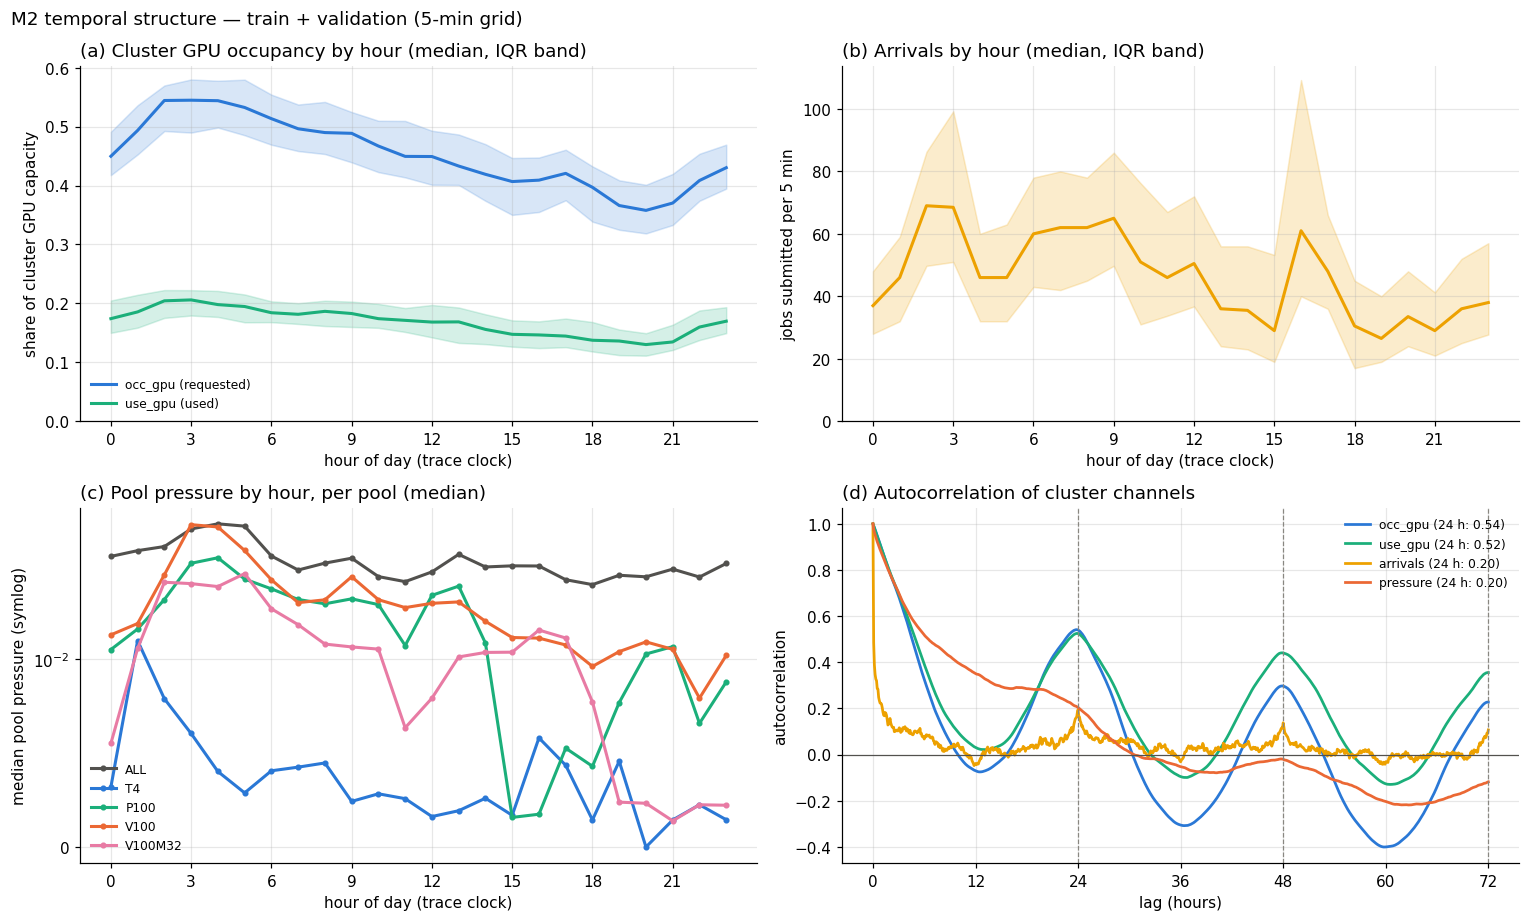

In [17]:
# F06: M2 temporal structure — hour-of-day profiles and autocorrelation (train + validation grid)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tevzi.data.split import T0, DAY

BLUE, ORANGE, AQUA, YELLOW, PINK, INK2, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#52514e', '#898781'
POOLS = ['ALL', 'T4', 'P100', 'V100', 'V100M32']
PCOL = dict(zip(POOLS, [INK2, BLUE, AQUA, ORANGE, PINK]))
grid = pd.read_parquet(PROC / 'm2_grid.parquet')
day = (grid.t - T0) / DAY
G = grid[(day >= 19) & (day < 52)].reset_index(drop=True)
G['hour'] = (G.t % DAY) // 3600                         # same clock as the M1 hour_sin / hour_cos features
G['arrivals'] = np.expm1(G.arr_count)                   # jobs submitted per 5 min
print(f'grid points (train + val): {len(G):,} | days: {len(G) * 300 / DAY:.1f}')

def profile(col):
    g = G.groupby('hour')[col]
    return g.median(), g.quantile(0.25), g.quantile(0.75)

def acf(x, max_lag):
    x = np.asarray(x, float); x = x - x.mean()
    n = len(x); f = np.fft.rfft(x, 2 * n)
    r = np.fft.irfft(f * np.conj(f))[:max_lag + 1]
    return r / r[0]

lags = np.arange(0, 72 * 12 + 1)                        # up to 72 h in 5-min steps
series = {'occ_gpu': BLUE, 'use_gpu': AQUA, 'arrivals': YELLOW, 'pressure': ORANGE}
A = pd.DataFrame({k: acf(G[k], lags[-1]) for k in series}, index=lags / 12)
pk = A.loc[[1, 6, 12, 24, 48]].round(3)
print('\nautocorrelation at selected lags (hours):'); print(pk.to_string())
amp = pd.DataFrame({c: profile(c)[0] for c in ['occ_gpu', 'use_gpu', 'arrivals', 'pressure']})
print('\nhour-of-day medians: max / min ratio'); print((amp.max() / amp.min()).round(2).to_string())
pp = pd.DataFrame({p: G.groupby('hour')[f'{p}:pool_pressure'].median() for p in POOLS})
pd.concat([pk.add_prefix('acf_').reset_index(names='lag_h').assign(table='acf'),
           amp.reset_index().assign(table='hourly_median'),
           pp.add_prefix('pool_pressure_').reset_index().assign(table='pool_pressure_hourly_median')]).round(4) \
  .to_csv(DRIVE / 'results/tables/midterm_m2_temporal.csv', index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
ax = axes[0, 0]
for col, c, lab in [('occ_gpu', BLUE, 'occ_gpu (requested)'), ('use_gpu', AQUA, 'use_gpu (used)')]:
    m, lo, hi = profile(col)
    ax.plot(m.index, m, color=c, lw=2, label=lab); ax.fill_between(m.index, lo, hi, color=c, alpha=0.18)
ax.set_ylabel('share of cluster GPU capacity'); ax.set_ylim(0, None)
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('(a) Cluster GPU occupancy by hour (median, IQR band)', loc='left')

ax = axes[0, 1]
m, lo, hi = profile('arrivals')
ax.plot(m.index, m, color=YELLOW, lw=2, label='arrivals'); ax.fill_between(m.index, lo, hi, color=YELLOW, alpha=0.2)
ax.set_ylabel('jobs submitted per 5 min'); ax.set_ylim(0, None)
ax.set_title('(b) Arrivals by hour (median, IQR band)', loc='left')

ax = axes[1, 0]
for p in POOLS:
    ax.plot(pp.index, pp[p], color=PCOL[p], lw=2, marker='o', ms=3, label=p)
ax.set_yscale('symlog', linthresh=0.01); ax.set_ylabel('median pool pressure (symlog)')
ax.legend(frameon=False, fontsize=8, ncol=1, loc='lower left')
ax.set_title('(c) Pool pressure by hour, per pool (median)', loc='left')
for a in (axes[0, 0], axes[0, 1], axes[1, 0]):
    a.set_xticks(range(0, 24, 3)); a.set_xlabel('hour of day (trace clock)')

ax = axes[1, 1]
for k, c in series.items():
    ax.plot(A.index, A[k], color=c, lw=1.8, label=f'{k} (24 h: {A.loc[24, k]:.2f})')
for h in (24, 48, 72):
    ax.axvline(h, color=MUTED, lw=0.8, ls='--')
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(0, 73, 12)); ax.set_xlabel('lag (hours)'); ax.set_ylabel('autocorrelation')
ax.legend(frameon=False, fontsize=8, loc='upper right')
ax.set_title('(d) Autocorrelation of cluster channels', loc='left')

fig.suptitle('M2 temporal structure — train + validation (5-min grid)', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 6, 'm2_daily_cycle')
plt.show()

all jobs with a submission time: 1,051,838 | model set: 714,273 | last day 68.9
period                   role  days  model_jobs  purged   kept  kept_%_of_model_set  in_burst  usage_label_%  group_history_%  jobs_per_day  pool_ALL_%  pool_T4_%  pool_P100_%  pool_V100_%  pool_V100M32_%
warmup  history features only  0–19      123831       0 123831                 17.3         0            1.2             63.7        6517.4        64.1       27.0          6.0          1.9             0.9
 train                    fit 19–45      281595     531 281064                 39.3         0           96.4             70.5       10830.6        60.9       28.1          7.0          2.6             1.4
   val   model selection (G3) 45–52       89412     801  88611                 12.4         0           98.7             70.6       12773.1        62.7       24.9          8.4          2.2             1.8
  test final evaluation, once 52–69      219435       0 219435                 30.7     19543       

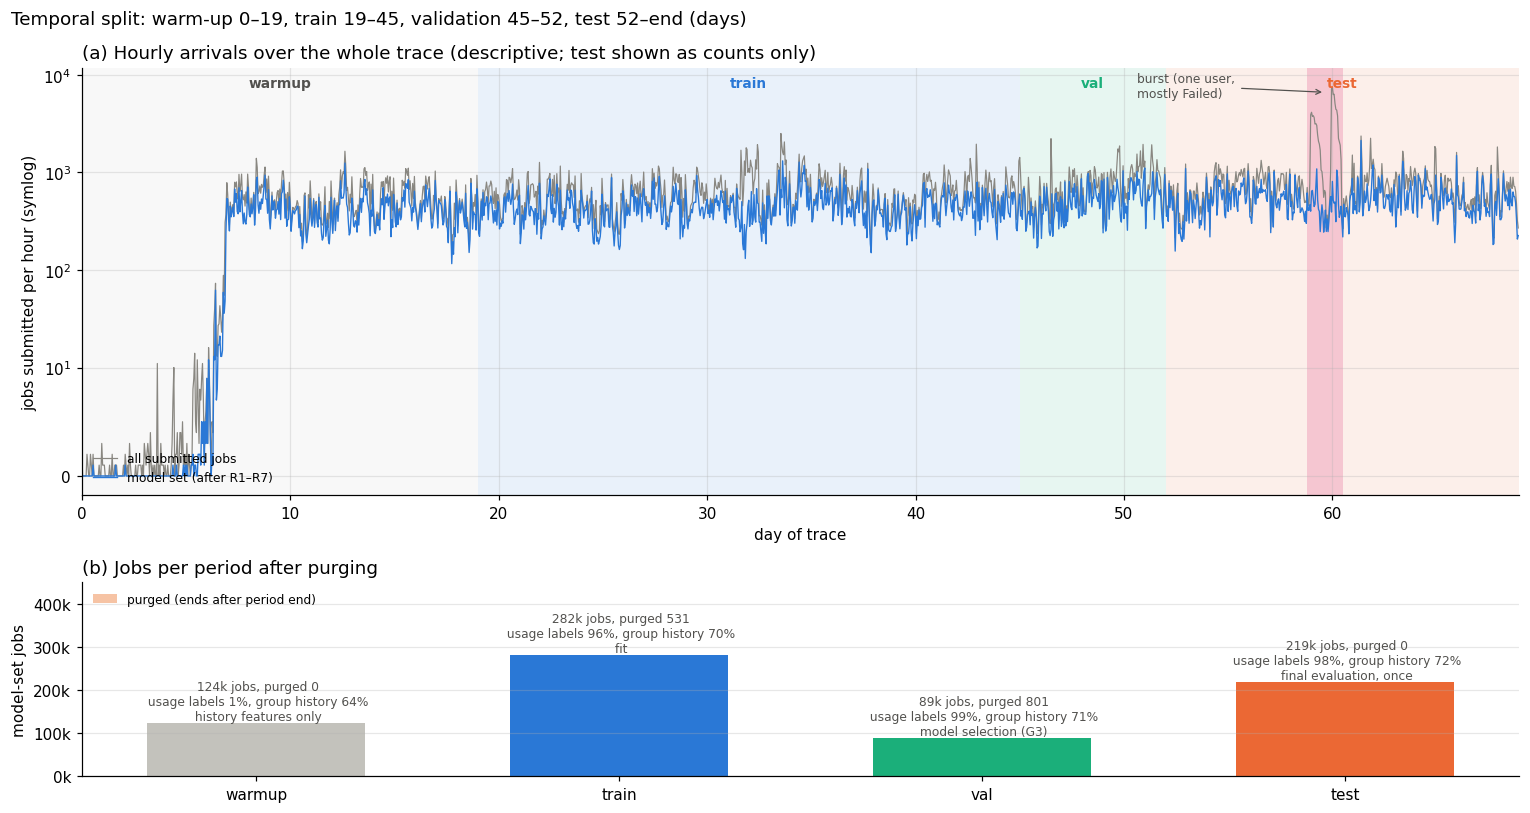

In [18]:
# F02 + T5: temporal split — hourly arrivals over the whole trace (descriptive), periods, purging, burst
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tevzi.data.split import T0, DAY, PERIODS, BURST_DAYS

PCOL = {'warmup': '#c3c2bc', 'train': '#2a78d6', 'val': '#1baf7a', 'test': '#eb6834'}
INK2, MUTED = '#52514e', '#898781'
jf = pd.read_parquet(PROC / 'jobs_flags.parquet', columns=['job_name', 'submit_time', 'model'])
tg = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'period', 'submit_day', 'purged', 'in_burst', 'has_usage'])
m1 = pd.read_parquet(PROC / 'm1_features.parquet', columns=['job_name', 'grp_rt_n'])
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'pool_key'])
jf = jf[jf.submit_time.notna()]
jf['day'] = (jf.submit_time - T0) / DAY
M = tg.merge(m1, on='job_name').merge(sn, on='job_name')
print(f'all jobs with a submission time: {len(jf):,} | model set: {len(M):,} | last day {jf.day.max():.1f}')

# T5: split summary — counts and coverage only (no target values; the test period stays closed)
order = ['warmup', 'train', 'val', 'test']
ROLE = {'warmup': 'history features only', 'train': 'fit', 'val': 'model selection (G3)', 'test': 'final evaluation, once'}
rows = []
for p in order:
    g = M[M.period == p]
    lo, hi = PERIODS[p]
    r = {'period': p, 'role': ROLE[p], 'days': f'{lo:g}–{min(hi, np.ceil(jf.day.max())):g}', 'model_jobs': len(g),
         'purged': int(g.purged.sum()), 'kept': int((~g.purged.astype(bool)).sum()),
         'kept_%_of_model_set': 100 * (~g.purged.astype(bool)).sum() / len(M),
         'in_burst': int(g.in_burst.sum()), 'usage_label_%': 100 * g.has_usage.mean(),
         'group_history_%': 100 * (g.grp_rt_n.fillna(0) > 0).mean(),
         'jobs_per_day': len(g) / (min(hi, jf.day.max()) - lo)}
    for k in ['ALL', 'T4', 'P100', 'V100', 'V100M32']:
        r[f'pool_{k}_%'] = 100 * (g.pool_key == k).mean()
    rows.append(r)
T5 = pd.DataFrame(rows)
T5.loc[len(T5)] = {'period': 'total', 'days': '', 'model_jobs': len(M), 'purged': int(M.purged.sum()),
                   'kept': int((~M.purged.astype(bool)).sum()), 'in_burst': int(M.in_burst.sum())}
print(T5.round(1).to_string(index=False))
T5.round(2).to_csv(DRIVE / 'results/tables/midterm_T5_split.csv', index=False)

# Figure: hourly arrivals (all jobs vs model set), period shading, burst, purge share per period
edges = np.arange(0, np.ceil(jf.day.max() * 24) + 1) / 24
h_all = np.histogram(jf.day, edges)[0]
h_mod = np.histogram(jf.loc[jf.model.astype(bool), 'day'], edges)[0]
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), gridspec_kw={'height_ratios': [2.2, 1]})
ax = axes[0]
for p in order:
    lo, hi = PERIODS[p]
    ax.axvspan(lo, min(hi, edges[-1]), color=PCOL[p], alpha=0.10, lw=0)
    ax.text((lo + min(hi, edges[-1])) / 2, 0.98, p, transform=ax.get_xaxis_transform(), ha='center', va='top',
            fontsize=9, color=PCOL[p] if p != 'warmup' else INK2, fontweight='bold')
ax.plot(edges[:-1], h_all, color=MUTED, lw=0.8, label='all submitted jobs')
ax.plot(edges[:-1], h_mod, color='#2a78d6', lw=0.9, label='model set (after R1–R7)')
ax.axvspan(*BURST_DAYS, color='#e87ba4', alpha=0.35, lw=0)
ax.annotate('burst (one user,\nmostly Failed)', xy=(np.mean(BURST_DAYS), np.percentile(h_all, 99.9)),
            xytext=(np.mean(BURST_DAYS) - 9, np.percentile(h_all, 99.9) * 0.9), fontsize=8, color=INK2,
            arrowprops=dict(arrowstyle='->', color=INK2, lw=0.8))
ax.set_yscale('symlog', linthresh=10); ax.set_ylabel('jobs submitted per hour (symlog)')
ax.set_xlim(0, edges[-1]); ax.set_xlabel('day of trace')
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('(a) Hourly arrivals over the whole trace (descriptive; test shown as counts only)', loc='left')

ax = axes[1]
t5 = T5[T5.period.isin(order)].set_index('period')
x = np.arange(len(order))
ax.bar(x, t5.kept, color=[PCOL[p] for p in order], width=0.6)
ax.bar(x, t5.purged, bottom=t5.kept, color='#f6c3a4', width=0.6, label='purged (ends after period end)')
for xi, p in enumerate(order):
    r = t5.loc[p]
    ax.text(xi, r.model_jobs, f' {r.model_jobs/1000:.0f}k jobs, purged {r.purged:,}\n usage labels {r["usage_label_%"]:.0f}%,'
            f' group history {r["group_history_%"]:.0f}%\n {r.role}', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_xticks(x, order); ax.set_ylabel('model-set jobs'); ax.set_ylim(0, t5.model_jobs.max() * 1.6)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax.legend(frameon=False, fontsize=8, loc='upper left'); ax.grid(axis='x', visible=False)
ax.set_title('(b) Jobs per period after purging', loc='left')

fig.suptitle('Temporal split: warm-up 0–19, train 19–45, validation 45–52, test 52–end (days)', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 2, 'temporal_split')
plt.show()

                    step                                                 description  removed  remaining  removed_%_of_all  remaining_%_of_all
                All jobs                                               pai_job_table        0    1055501              0.00              100.00
       R1_not_terminated                                Job status is not Terminated   323146     732355             30.62               69.38
             R2_cpu_only                                      No task requests a GPU    17452     714903              1.65               67.73
      R3_missing_request    Missing CPU/memory request, or GPU type without plan_gpu        0     714903              0.00               67.73
     R4_zero_cpu_request                                       A task requests 0 CPU        0     714903              0.00               67.73
R5_request_over_capacity A request exceeds the largest machine of the requested type       83     714820              0.01               67.72

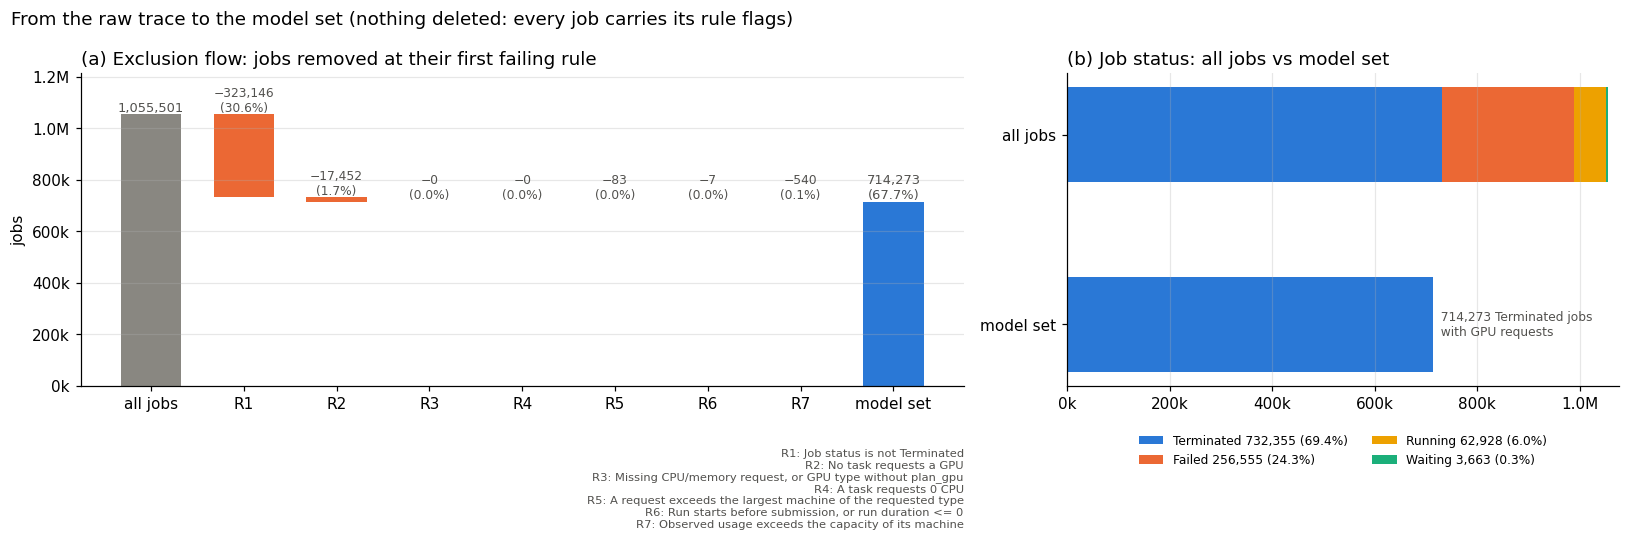

In [19]:
# F01 + T2: data flow — exclusion rules R1–R7 (first failing rule) from all jobs to the model set
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tevzi.data.cleaning import RULES, RULE_ORDER

BLUE, ORANGE, INK2, MUTED = '#2a78d6', '#eb6834', '#52514e', '#898781'
jf = pd.read_parquet(PROC / 'jobs_flags.parquet', columns=['job_name', 'status', 'first_rule', 'model', 'm2_occupancy'])
N = len(jf)
fr = jf.first_rule.value_counts()
rows, remaining = [{'step': 'All jobs', 'description': 'pai_job_table', 'removed': 0, 'remaining': N}], N
for r in RULE_ORDER:
    k = int(fr.get(r, 0)); remaining -= k
    rows.append({'step': r, 'description': RULES[r], 'removed': k, 'remaining': remaining})
T2 = pd.DataFrame(rows)
T2['removed_%_of_all'] = 100 * T2.removed / N
T2['remaining_%_of_all'] = 100 * T2.remaining / N
assert T2.remaining.iloc[-1] == int(jf.model.astype(bool).sum()), 'flow does not end at the model set'
print(T2.round(2).to_string(index=False))
T2.round(3).to_csv(DRIVE / 'results/tables/midterm_T2_exclusion_flow.csv', index=False)

st = jf.status.value_counts()
print('\njob status (all jobs):'); print(st.to_string())
print(f'\nM2 background-load set (Terminated, valid requests and run interval, CPU-only included): '
      f'{int(jf.m2_occupancy.astype(bool).sum()):,}')
xs = pd.crosstab(jf.first_rule, jf.status).reindex(['kept'] + RULE_ORDER).fillna(0).astype(int)
print('\nfirst rule x status:'); print(xs.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]                                            # (a) waterfall
labels = ['all jobs'] + [r.split('_', 1)[0] for r in RULE_ORDER] + ['model set']
x = np.arange(len(labels))
ax.bar(0, N, color=MUTED, width=0.65)
prev = N
for i, r in enumerate(RULE_ORDER, start=1):
    k = int(fr.get(r, 0))
    ax.bar(i, k, bottom=prev - k, color=ORANGE, width=0.65)
    ax.text(i, prev, f'−{k:,}\n({100*k/N:.1f}%)', ha='center', va='bottom', fontsize=8, color=INK2)
    prev -= k
ax.bar(len(labels) - 1, prev, color=BLUE, width=0.65)
ax.text(0, N, f'{N:,}', ha='center', va='bottom', fontsize=8.5, color=INK2)
ax.text(len(labels) - 1, prev, f'{prev:,}\n({100*prev/N:.1f}%)', ha='center', va='bottom', fontsize=8.5, color=INK2)
ax.set_xticks(x, labels); ax.set_ylim(0, N * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1000:.0f}k'))
ax.set_ylabel('jobs'); ax.grid(axis='x', visible=False)
ax.set_title('(a) Exclusion flow: jobs removed at their first failing rule', loc='left')
legend = '\n'.join(f'{r.split("_", 1)[0]}: {RULES[r]}' for r in RULE_ORDER)
ax.text(1.0, -0.2, legend, transform=ax.transAxes, ha='right', va='top', fontsize=7.5, color=INK2)

ax = axes[1]                                            # (b) status of all jobs vs model set
cats = list(st.index)
cols = {'Terminated': BLUE, 'Failed': ORANGE, 'Running': '#eda100', 'Waiting': '#1baf7a'}
left = 0
for c in cats:
    v = st[c]
    ax.barh(0, v, left=left, color=cols.get(c, MUTED), height=0.5, label=f'{c} {v:,} ({100*v/N:.1f}%)')
    left += v
ax.barh(1, prev, color=BLUE, height=0.5)
ax.text(prev, 1, f'  {prev:,} Terminated jobs\n  with GPU requests', va='center', fontsize=8, color=INK2)
ax.set_yticks([0, 1], ['all jobs', 'model set']); ax.invert_yaxis(); ax.set_xlim(0, N * 1.02)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1000:.0f}k'))
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('(b) Job status: all jobs vs model set', loc='left'); ax.grid(axis='y', visible=False)

fig.suptitle('From the raw trace to the model set (nothing deleted: every job carries its rule flags)', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 1, 'exclusion_flow')
plt.show()

                                      component modality  missing     of  missing_%                                                         reason                                                   strategy
                M2 window (24 steps + snapshot)       M2        0 369675        0.0                                                              —                      none needed; mask kept for generality
                 M1 request / identity features       M1        0 369675        0.0                                                              —                                                          —
                      M1 group run-time history       M1   109019 369675       29.5               first job of a group (84% of groups are one-off) GBM: native NaN; DL: 0 + indicator; reported as own subset
                         M1 group usage history       M1   115925 369675       31.4                        no earlier group job with a usage label                              

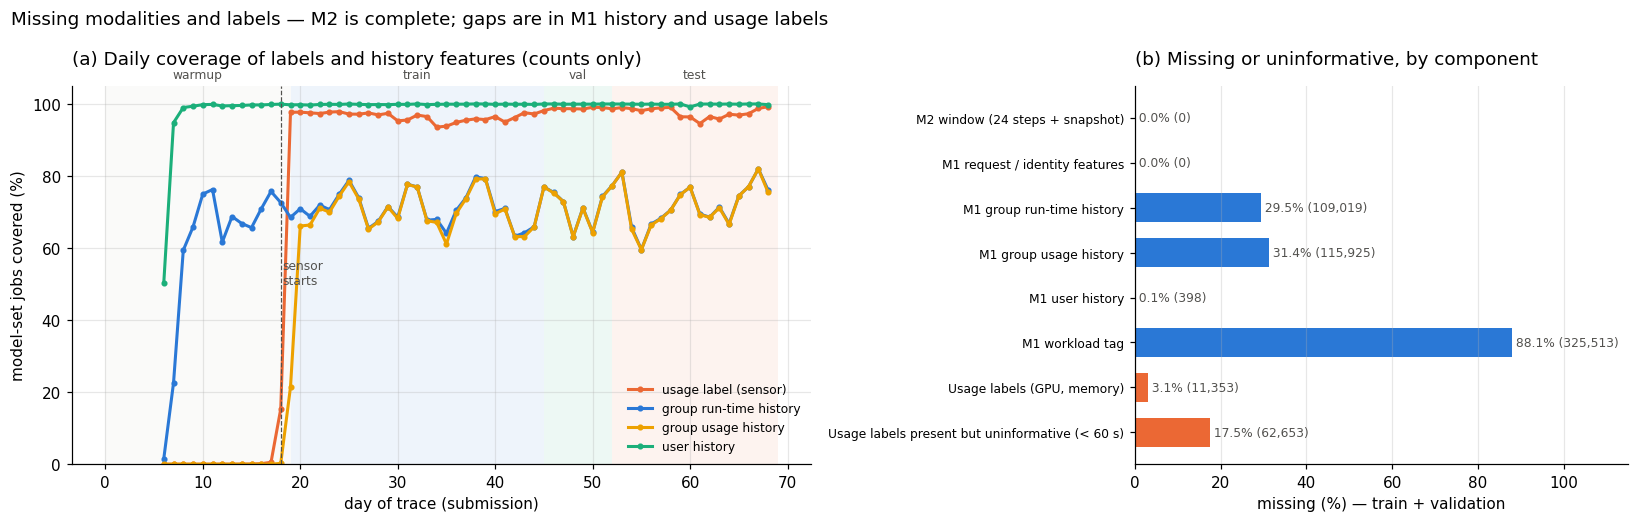

In [20]:
# F14 + T4: missing and uninformative modalities — what is missing, how much, why, and the strategy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tevzi.data.split import T0, DAY, PERIODS

BLUE, ORANGE, AQUA, YELLOW, INK2, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#52514e', '#898781'
tg = pd.read_parquet(PROC / 'targets.parquet', columns=['job_name', 'period', 'submit_day', 'purged', 'has_usage', 'run_time'])
m1 = pd.read_parquet(PROC / 'm1_features.parquet',
                     columns=['job_name', 'grp_rt_n', 'usr_rt_n', 'grp_use_n', 'workload_missing'])
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet', columns=['job_name', 'k_last'])
M = tg.merge(m1, on='job_name').merge(sn, on='job_name')
M['grp_hist'] = M.grp_rt_n.fillna(0) > 0
M['usr_hist'] = M.usr_rt_n.fillna(0) > 0
M['grp_use_hist'] = M.grp_use_n.fillna(0) > 0
M['m2_full'] = M.k_last >= 23
TV = M[M.period.isin(['train', 'val']) & ~M.purged.astype(bool)]
L = TV[TV.has_usage.astype(bool)]
n = len(TV)

def row(component, modality, missing, base, reason, strategy):
    return {'component': component, 'modality': modality, 'missing': int(missing), 'of': int(base),
            'missing_%': 100 * missing / base, 'reason': reason, 'strategy': strategy}

T4 = pd.DataFrame([
    row('M2 window (24 steps + snapshot)', 'M2', (~TV.m2_full).sum(), n, '—', 'none needed; mask kept for generality'),
    row('M1 request / identity features', 'M1', 0, n, '—', '—'),
    row('M1 group run-time history', 'M1', (~TV.grp_hist).sum(), n, 'first job of a group (84% of groups are one-off)',
        'GBM: native NaN; DL: 0 + indicator; reported as own subset'),
    row('M1 group usage history', 'M1', (~TV.grp_use_hist).sum(), n, 'no earlier group job with a usage label',
        'same as above'),
    row('M1 user history', 'M1', (~TV.usr_hist).sum(), n, "user's first job", 'same as above'),
    row('M1 workload tag', 'M1', TV.workload_missing.astype(bool).sum(), n, 'not recorded in the source table',
        "'missing' category + indicator; ablation candidate"),
    row('Usage labels (GPU, memory)', 'labels', (~TV.has_usage.astype(bool)).sum(), n,
        'no sensor record for the main task', 'masked in usage losses; job kept for run time'),
    row('Usage labels present but uninformative (< 60 s)', 'labels', (L.run_time < 60).sum(), len(L),
        'job ends before GPU work / before the peak is reached (A6, A7)', 'rule fixed before results in Stage 3.4'),
])
print(T4.round(1).to_string(index=False))
T4.round(2).to_csv(DRIVE / 'results/tables/midterm_T4_missing_modality.csv', index=False)

# Daily coverage over the whole trace (counts only; no target values)
M['day'] = np.floor(M.submit_day).astype(int)
D = M.groupby('day').agg(jobs=('job_name', 'size'), usage=('has_usage', 'mean'), grp=('grp_hist', 'mean'),
                         usr=('usr_hist', 'mean'), grp_use=('grp_use_hist', 'mean'))
D = D[D.jobs >= 50]                                     # days with almost no arrivals are not shown
print(f'\ndays shown: {len(D)} (days with >= 50 model-set jobs)')
print('usage-label coverage around the sensor start:'); print((100 * D.usage.loc[15:22]).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]
for p, (lo, hi) in PERIODS.items():
    ax.axvspan(lo, min(hi, D.index.max() + 1), color={'warmup': '#c3c2bc', 'train': BLUE, 'val': AQUA, 'test': ORANGE}[p], alpha=0.08, lw=0)
    ax.text((lo + min(hi, D.index.max() + 1)) / 2, 1.02, p, transform=ax.get_xaxis_transform(), ha='center', fontsize=8, color=INK2)
for col, c, lab in [('usage', ORANGE, 'usage label (sensor)'), ('grp', BLUE, 'group run-time history'),
                    ('grp_use', YELLOW, 'group usage history'), ('usr', AQUA, 'user history')]:
    ax.plot(D.index, 100 * D[col], color=c, lw=2, marker='o', ms=3, label=lab)
ax.axvline(18, color=INK2, lw=0.8, ls='--'); ax.text(18.2, 50, 'sensor\nstarts', fontsize=8, color=INK2)
ax.set_ylim(0, 105); ax.set_xlabel('day of trace (submission)'); ax.set_ylabel('model-set jobs covered (%)')
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('(a) Daily coverage of labels and history features (counts only)', loc='left', pad=14)

ax = axes[1]
t = T4.iloc[::-1]
cols = [ORANGE if m == 'labels' else BLUE if m == 'M1' else AQUA for m in t.modality]
ax.barh(range(len(t)), t['missing_%'], color=cols, height=0.65)
for i, (v, k) in enumerate(zip(t['missing_%'], t.missing)):
    ax.text(v, i, f' {v:.1f}% ({k:,})', va='center', fontsize=8, color=INK2)
ax.set_yticks(range(len(t)), t.component, fontsize=8); ax.set_xlim(0, 115)
ax.set_xlabel('missing (%) — train + validation'); ax.grid(axis='y', visible=False)
ax.set_title('(b) Missing or uninformative, by component', loc='left', pad=14)

fig.suptitle('Missing modalities and labels — M2 is complete; gaps are in M1 history and usage labels', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 14, 'missing_modality')
plt.show()

       component                                         type                                                    source                                                                    shape                                                             groups                   known at   jobs
 M1 job features                     tabular, one row per job   job, task, instance, group_tag tables (+ as-of history)                                  46 features (42 numeric, 4 categorical) A_requests 11, B_structure 6, C_identity 3, D_history 22, E_time 4                 submission 369675
M2 cluster state multivariate time series, one window per job job + instance + machine_spec (cluster-level aggregation) (24 + 1) × 11 = 24 steps × 5 min + snapshot; 7 cluster + 4 pool channels                             pool = requested GPU type (MISC → ALL) strictly before submission 369675
         Targets                      regression (multi-task)      instance (run time), sensor (usage) of the main tas

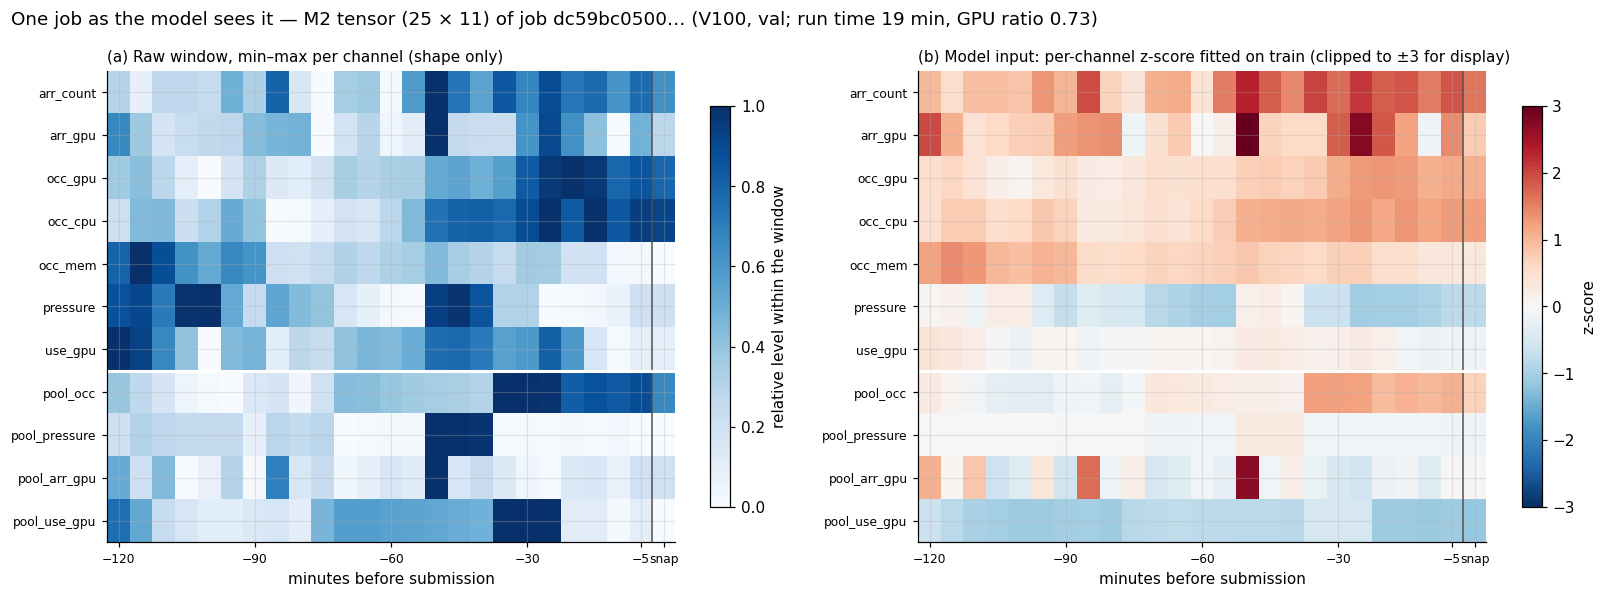

In [21]:
# T1 + T6 (+ F29): modality definitions and one rule-selected job as the model sees it (M1 vector, M2 tensor, labels)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tevzi.features.m1 import FEATURE_GROUPS, CATEGORICAL
from tevzi.features.m2 import windows, fit_scaler, apply_scaler, CHANNELS, CLUSTER_CHANNELS, POOL_CHANNELS, STEP
from tevzi.models.preprocess import NumericScaler, CategoryMap

INK2 = '#52514e'
N_STEPS = 24
tg = pd.read_parquet(PROC / 'targets.parquet')
m1 = pd.read_parquet(PROC / 'm1_features.parquet')
sn = pd.read_parquet(PROC / 'm2_snapshots.parquet')
grid = pd.read_parquet(PROC / 'm2_grid.parquet')
keep = tg[tg.period.isin(['train', 'val']) & ~tg.purged.astype(bool)][['job_name', 'period']]
num_cols = [c for c in m1.columns if c not in ('job_name', *CATEGORICAL)]

# ---- T1: modality definitions (counts from the data, train + validation)
T1 = pd.DataFrame([
    {'component': 'M1 job features', 'type': 'tabular, one row per job', 'source': 'job, task, instance, group_tag tables (+ as-of history)',
     'shape': f'{len(num_cols) + len(CATEGORICAL)} features ({len(num_cols)} numeric, {len(CATEGORICAL)} categorical)',
     'groups': ', '.join(f'{g} {len(v)}' for g, v in FEATURE_GROUPS.items()), 'known at': 'submission', 'jobs': len(keep)},
    {'component': 'M2 cluster state', 'type': 'multivariate time series, one window per job', 'source': 'job + instance + machine_spec (cluster-level aggregation)',
     'shape': f'({N_STEPS} + 1) × {len(CHANNELS)} = {N_STEPS} steps × {STEP // 60} min + snapshot; {len(CLUSTER_CHANNELS)} cluster + {len(POOL_CHANNELS)} pool channels',
     'groups': 'pool = requested GPU type (MISC → ALL)', 'known at': 'strictly before submission', 'jobs': len(keep)},
    {'component': 'Targets', 'type': 'regression (multi-task)', 'source': 'instance (run time), sensor (usage) of the main task',
     'shape': '3: log1p(run time), GPU ratio, peak memory ratio', 'groups': 'usage labels masked when missing',
     'known at': 'after the job ends', 'jobs': len(keep)},
    {'component': 'Key', 'type': 'job_name', 'source': 'all tables', 'shape': '1:1 across M1, M2, targets (T3)', 'groups': '',
     'known at': '', 'jobs': len(keep)},
])
print(T1.to_string(index=False))
T1.to_csv(DRIVE / 'results/tables/midterm_T1_modalities.csv', index=False)

# ---- Rule-selected example: validation, V100 pool, group history, usage label; run time closest to the subset median
cand = (tg[tg.period.eq('val') & ~tg.purged.astype(bool) & tg.has_usage.astype(bool)]
        .merge(sn[['job_name', 'pool_key']], on='job_name').merge(m1[['job_name', 'grp_rt_n']], on='job_name'))
cand = cand[(cand.pool_key == 'V100') & (cand.grp_rt_n.fillna(0) > 0)]
med = cand.log_run_time.median()
job = cand.iloc[int(np.argmin((cand.log_run_time - med).abs().to_numpy()))].job_name
print(f'\nexample job (rule: val, V100 pool, group history, usage label, run time closest to the median of {len(cand):,} candidates): {job}')

# ---- M1: raw value, GBM input, DL input (scalers fitted on train only, as in Stage 3.2)
trn = m1.merge(keep, on='job_name')
trn = trn[trn.period.eq('train')]
scaler = NumericScaler.fit(trn, num_cols)
cmap = CategoryMap.fit(trn, CATEGORICAL)
row = m1[m1.job_name == job]
Z = scaler.transform(row).iloc[0]
C = cmap.transform(row).iloc[0]
group_of = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
recs = []
for c in CATEGORICAL + num_cols:
    raw = row[c].iloc[0]
    if c in CATEGORICAL:
        dl = f'embedding index {int(C[c])}' + (' (other)' if C[c] == 0 else '')
    else:
        dl = round(float(Z[c]), 3)
    recs.append({'feature': c, 'group': group_of.get(c, ''), 'raw (GBM input)': raw if not isinstance(raw, float) else round(raw, 4),
                 'log1p before z': c in scaler.log_cols, 'DL input': dl})
for c in scaler.na_cols:
    recs.append({'feature': f'{c}_isna', 'group': 'missing indicator', 'raw (GBM input)': '', 'log1p before z': False,
                 'DL input': float(scaler.transform(row)[f'{c}_isna'].iloc[0])})
T6a = pd.DataFrame(recs)
print(f'\nM1 vector: {len(CATEGORICAL) + len(num_cols)} features -> DL input: {len(num_cols)} scaled numeric + '
      f'{len(scaler.na_cols)} missing indicators = {len(scaler.out_cols)} values, plus {len(CATEGORICAL)} embedding indices')
with pd.option_context('display.max_rows', 100, 'display.width', 160):
    print(T6a.to_string(index=False))

# ---- M2: raw window and model input (per-channel z-score fitted on train windows, as features/m2.fit_scaler)
s_tr = sn[sn.job_name.isin(keep.loc[keep.period == 'train', 'job_name'])]
X_tr, v_tr = windows(grid, s_tr, N_STEPS)
mean, std = fit_scaler(X_tr, v_tr)
del X_tr, v_tr
s_job = sn[sn.job_name == job]
X, valid = windows(grid, s_job, N_STEPS)
Xs = apply_scaler(X, mean, std)
steps = [f't-{(N_STEPS - i) * STEP // 60} min' for i in range(N_STEPS)] + ['snapshot (submit)']
T6b = pd.DataFrame(X[0], columns=CHANNELS, index=steps)
print(f'\nM2 tensor: {X.shape[1:]} (steps x channels), valid steps {int(valid.sum())}/{N_STEPS}, pool {s_job.pool_key.iloc[0]}')
print(T6b.round(4).to_string())

y = tg[tg.job_name == job][['run_time', 'log_run_time', 'gpu_ratio', 'mem_ratio', 'wait_time']].iloc[0]
print('\nlabels:', y.round(4).to_dict())
T6a.to_csv(DRIVE / 'results/tables/midterm_T6a_example_m1.csv', index=False)
T6b.to_csv(DRIVE / 'results/tables/midterm_T6b_example_m2.csv')

# ---- F29: the same job's M2 input, raw and as the network sees it
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1]})
for ax, data, title, cmap_, lab in [
        (axes[0], (X[0] - X[0].min(0)) / np.where(np.ptp(X[0], 0) > 0, np.ptp(X[0], 0), 1), '(a) Raw window, min–max per channel (shape only)', 'Blues', 'relative level within the window'),
        (axes[1], np.clip(Xs[0], -3, 3), '(b) Model input: per-channel z-score fitted on train (clipped to ±3 for display)', 'RdBu_r', 'z-score')]:
    im = ax.imshow(data.T, aspect='auto', cmap=cmap_, vmin=None if cmap_ == 'Blues' else -3, vmax=None if cmap_ == 'Blues' else 3)
    ax.set_yticks(range(len(CHANNELS)), CHANNELS, fontsize=8)
    ax.set_xticks([0, 6, 12, 18, 23, 24], ['−120', '−90', '−60', '−30', '−5', 'snap'], fontsize=8)
    ax.axvline(23.5, color=INK2, lw=1)
    ax.axhline(len(CLUSTER_CHANNELS) - 0.5, color='white', lw=2)
    ax.set_xlabel('minutes before submission'); ax.set_title(title, loc='left', fontsize=10)
    fig.colorbar(im, ax=ax, label=lab, shrink=0.85)
fig.suptitle(f'One job as the model sees it — M2 tensor (25 × 11) of job {job[:10]}… '
             f'(V100, val; run time {y.run_time/60:.0f} min, GPU ratio {y.gpu_ratio:.2f})', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
save_fig(fig, 29, 'input_example_m2')
plt.show()

In [22]:
# Final check: every midterm figure and table the plan needs exists on Drive (and is not empty)
from pathlib import Path
FIGS = ['F01_exclusion_flow', 'F02_temporal_split', 'F03_target_distributions', 'F04_requests_representation',
        'F05_*', 'F06_m2_daily_cycle', 'F07_matching_example', 'F08_pressure_vs_wait', 'F09_m2_vs_machine_metric',
        'F10_preprocessing_before_after', 'F11_failed_load_before_after', 'F12_label_quality_by_duration',
        'F12_label_quality_examples', 'F14_missing_modality', 'F15_categorical_features', 'F16_user_group_concentration',
        'F17_history_signal', 'F18_request_vs_usage', 'F22_conditional_contribution', 'F23_target_relations',
        'F29_input_example_m2']
TABS = ['T1_modalities', 'T2_exclusion_flow', 'T3_matching', 'T4_missing_modality', 'T5_split', 'T6a_example_m1',
        'T6b_example_m2', 'T7_summary_stats', 'concentration', 'target_correlations', 'target_correlations_by_duration',
        'label_quality_by_duration', 'label_quality_examples', 'label_quality_extreme_jobs', 'preprocessing_effect',
        'failed_load_sensitivity', 'pressure_vs_wait', 'm2_vs_machine_metric', 'conditional_contribution', 'm2_temporal']
fig_dir, tab_dir = DRIVE / 'results/figures', DRIVE / 'results/tables'
missing = []
for pat in FIGS:
    hits = sorted(fig_dir.glob(pat + '.png' if not pat.endswith('*') else pat))
    ok = bool(hits) and all(h.stat().st_size > 10_000 for h in hits)
    print(f"{'ok ' if ok else 'MISSING'}  figure  {hits[0].name if hits else pat + '.png'}"
          + (f'  ({hits[0].stat().st_size/1e3:.0f} kB)' if hits else ''))
    if not ok: missing.append(pat)
for name in TABS:
    p = tab_dir / f'midterm_{name}.csv'
    ok = p.exists() and p.stat().st_size > 100
    print(f"{'ok ' if ok else 'MISSING'}  table   {p.name}")
    if not ok: missing.append(name)
print(f'\n{len(FIGS)} figures, {len(TABS)} tables checked -> ' + ('all present' if not missing else f'missing: {missing}'))

ok   figure  F01_exclusion_flow.png  (208 kB)
ok   figure  F02_temporal_split.png  (479 kB)
ok   figure  F03_target_distributions.png  (173 kB)
ok   figure  F04_requests_representation.png  (211 kB)
ok   figure  F05_m2_channel_distributions.png  (358 kB)
ok   figure  F06_m2_daily_cycle.png  (597 kB)
ok   figure  F07_matching_example.png  (220 kB)
ok   figure  F08_pressure_vs_wait.png  (267 kB)
ok   figure  F09_m2_vs_machine_metric.png  (369 kB)
ok   figure  F10_preprocessing_before_after.png  (366 kB)
ok   figure  F11_failed_load_before_after.png  (446 kB)
ok   figure  F12_label_quality_by_duration.png  (210 kB)
ok   figure  F12_label_quality_examples.png  (409 kB)
ok   figure  F14_missing_modality.png  (287 kB)
ok   figure  F15_categorical_features.png  (180 kB)
ok   figure  F16_user_group_concentration.png  (102 kB)
ok   figure  F17_history_signal.png  (366 kB)
ok   figure  F18_request_vs_usage.png  (287 kB)
ok   figure  F22_conditional_contribution.png  (179 kB)
ok   figure  F23_tar